# Score evaluation of the Shannon-target sensitivity model
Copy of `evaluate_scores.ipynb` for the model trained on Shannon diversity (reviewer 1, point 4); only the USER INPUT cell differs.

To run this notebook, install the project into the uv environment once from the repository root (`uv pip install --no-deps -e .`, repeat after `uv sync`) and execute it from `results/` with `../.venv/bin/python -m nbconvert --to notebook --execute --inplace evaluate_scores_shannon.ipynb`, or open it in Jupyter with the `.venv` kernel.


## Setup

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import mannwhitneyu

from src.utils_eval_score import (
    _get_ordinal_suffix,
    _plot_score_after_nth_abx_exposure,
    _plot_score_over_age,
    _select_samples_around_nth_abx_exposure,
    display_scatterplot_w_scores,
    get_scores_n_abx_info,
    plot_time_between_abx_exposures,
    plot_trajectory,
)
from src.utils_meta import display_diet_information

%load_ext autoreload
%autoreload 2
%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans"})
plt.style.use("tableau-colorblind10")

warnings.filterwarnings("ignore", category=FutureWarning)
# avg. number of days per month
DAYS_PER_MONTH = 30.437

USER input: define the inferred model and linked datasets to evaluate here:

In [2]:
#### USER INPUT START

# model ID
ID = 1

# name of the model
model_name = f"saved_models_microbial_novel_alpha_div_shannon/id-{ID}"
# which model version to evaluate: "best" or "last"
point_to_evaluate = "best"

# name of feature dataset used for model
ft_name = "ft_vat19_anomaly_v20240806_entero_genus"
# name of abx time-series used for model
abx_ts_name = "ts_vat19_abx_v20240806"

# limit evaluation to time range up to this many months (if None no limit is set
# and all scores are evaluated)
limit_months = 24.0

# whether to group samples prior to abx exposure in analysis
group_samples = True

# how many samples prior and after abx exposure to consider
min_samples = -3.0
max_samples = 6.0

# whether to filter noabx score samples by having at least 1 obs prior to cutoff
no_filter = True

# whether to display diet info after 1st, 2nd, 3rd abx exposure plots
display_diet_info = True

# whether to have max. resolution of 0.5 months or not
max_resolution = False

# scaling factor options:
scaling_factors_used = True

# if scaling_factors_used is True, then the following options are required:
# non-centered = "nc_std" or centered = "std"
stddev_type = "nc_std"
# moving average window size: 30 or 10
moving_avg = 10
# whether to remove duplicates: "--RD-True" or ""
duplicates = "--RD-True"
# using lower bound of 1 for SFs: "lower_bound-1" or ""
lower_bound = ""

#### USER INPUT END

## Prepare data

In [3]:
base_path = f"../data/{model_name}/anomaly_detection/"

res_n_group = f"g{str(group_samples)[0]}_maxres{str(max_resolution)[0]}"

if scaling_factors_used:
    print("Scaling factors used.")
    folder_name = f"using-SF_{stddev_type}_z_scores--moving_avg-{moving_avg}-cummax{lower_bound}{duplicates}"

    scores_path = f"{base_path}scores_{point_to_evaluate}_normal/{folder_name}/"
    evaluation_path = f"{base_path}evaluation_{point_to_evaluate}_overall_{res_n_group}_{stddev_type}_ma{moving_avg}{duplicates.replace('-', '_').lower()}/"
else:
    scores_path = f"{base_path}scores_{point_to_evaluate}_normal/"
    evaluation_path = (
        f"{base_path}evaluation_{point_to_evaluate}_overall_{res_n_group}_no_scaling/"
    )
if not os.path.exists(evaluation_path):
    os.makedirs(evaluation_path)


Scaling factors used.


In [4]:
noabx_train, noabx_val, abx_scores_flat, abx_df, abx_age_at_all = get_scores_n_abx_info(
    scores_path, ft_name, limit_months, abx_ts_name, no_filter=no_filter
)


## Score after abx exposure 1st, 2nd and 3rd


### score_1, score_2 and score_3 respectively

(236, 25)
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_score_1.pdf


../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/diet_milk_after_abx1st.pdf


../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/diet_weaning_after_abx1st.pdf
(148, 25)


Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_score_2.pdf


../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/diet_milk_after_abx2nd.pdf
../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/diet_weaning_after_abx2nd.pdf


(89, 25)
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx3rd_score_3.pdf


../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/diet_milk_after_abx3rd.pdf
../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/diet_weaning_after_abx3rd.pdf


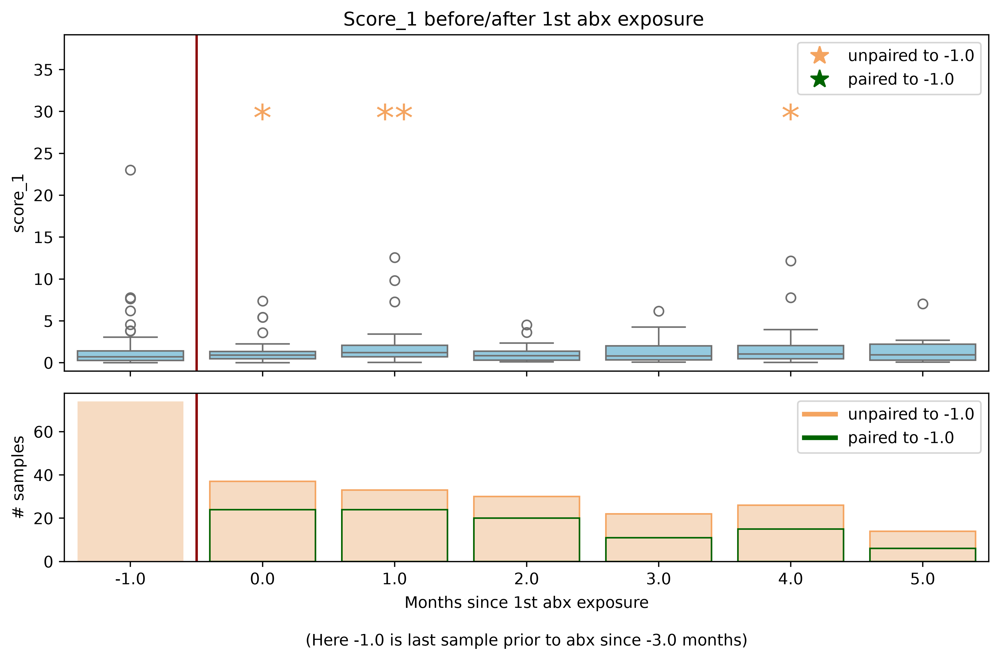

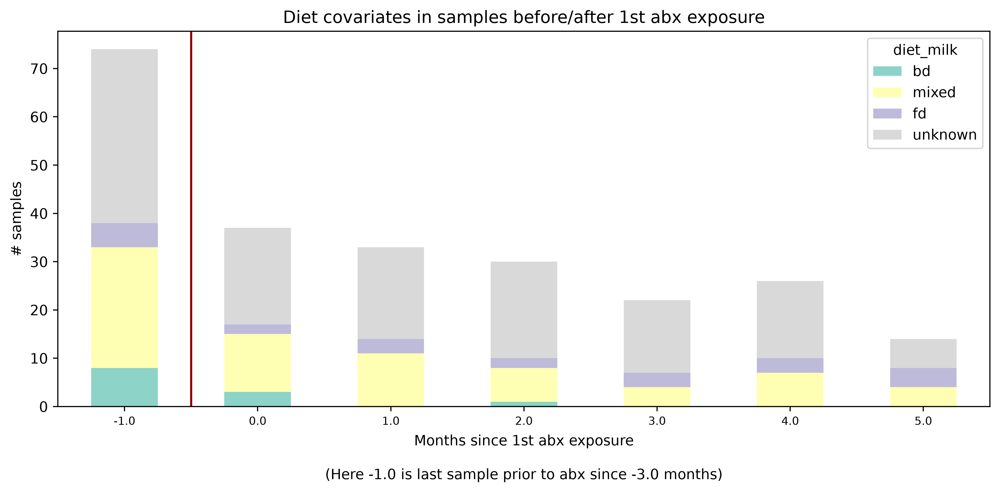

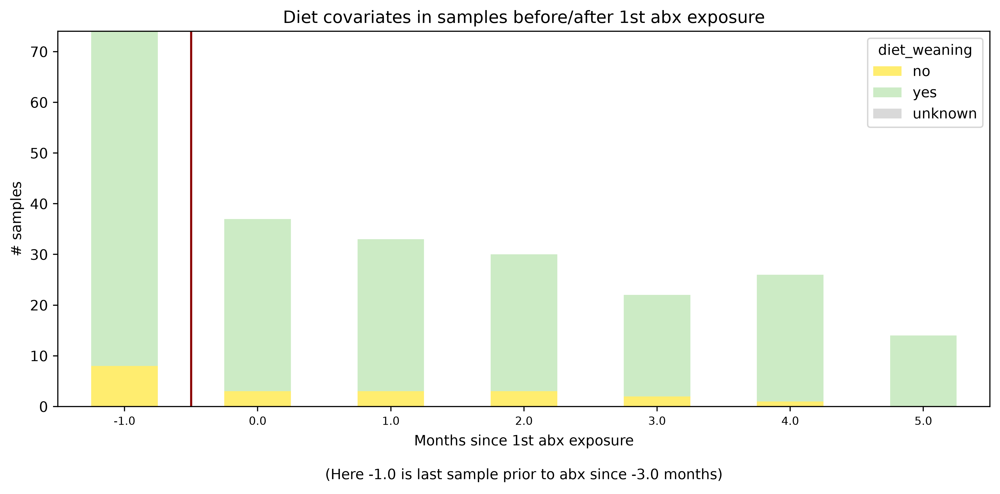

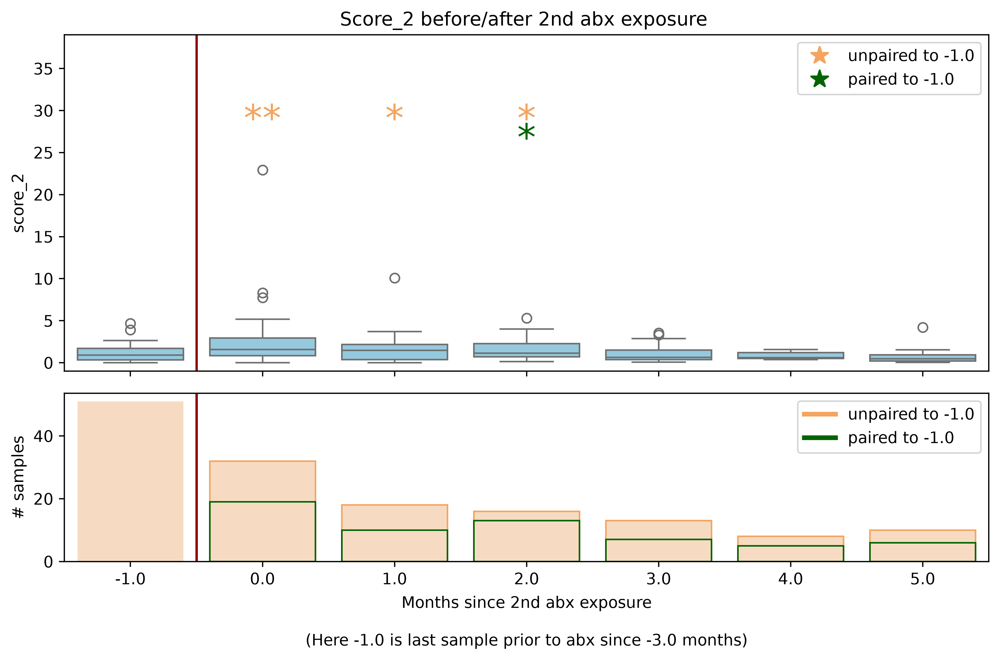

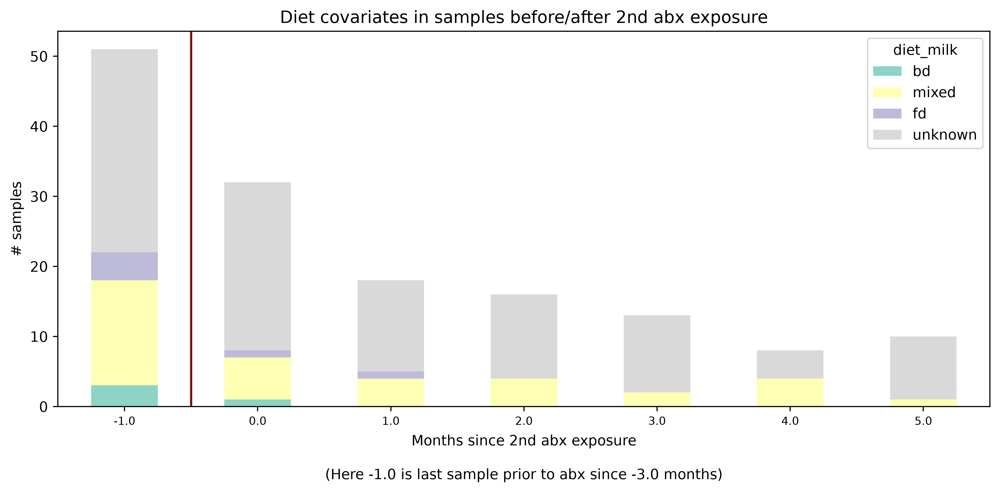

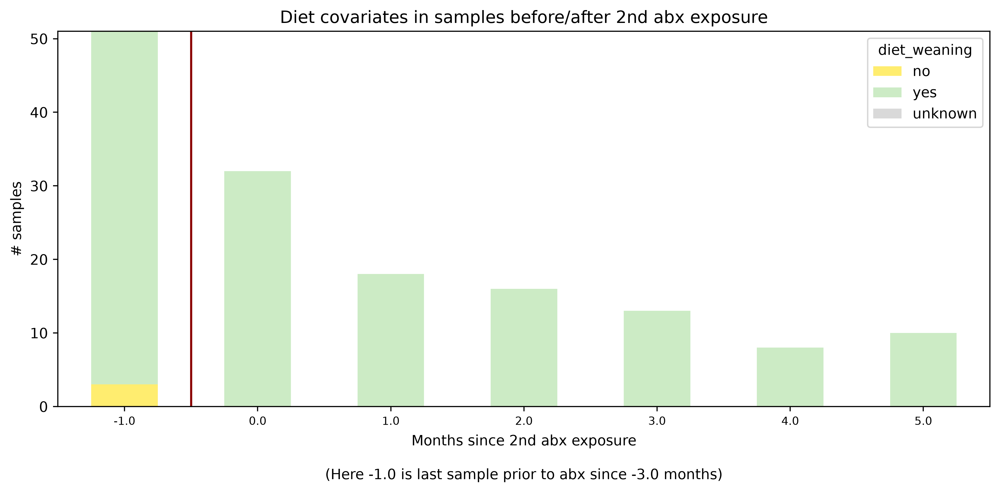

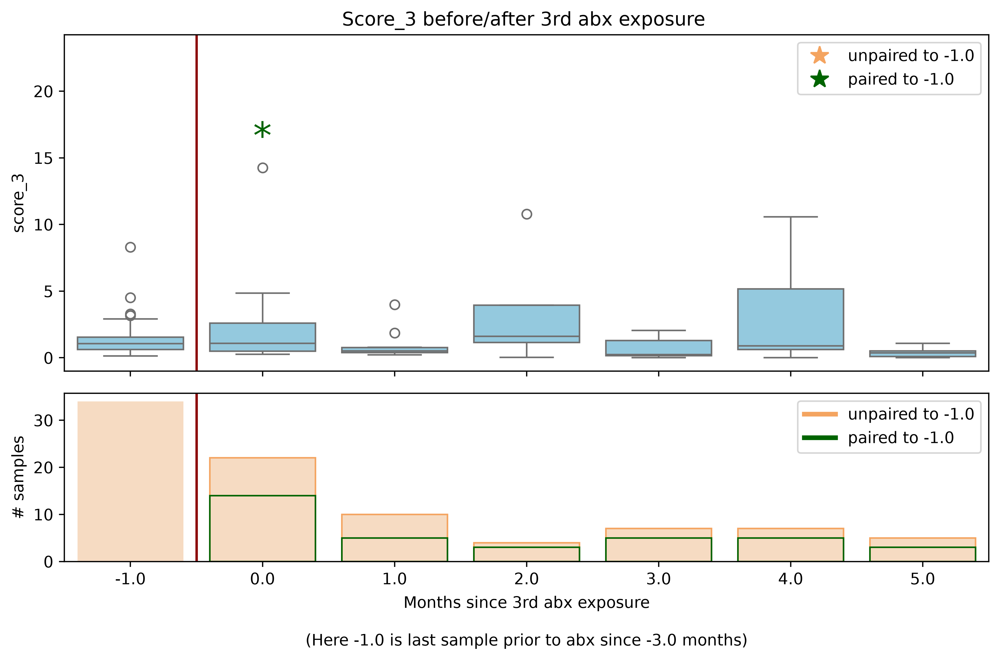

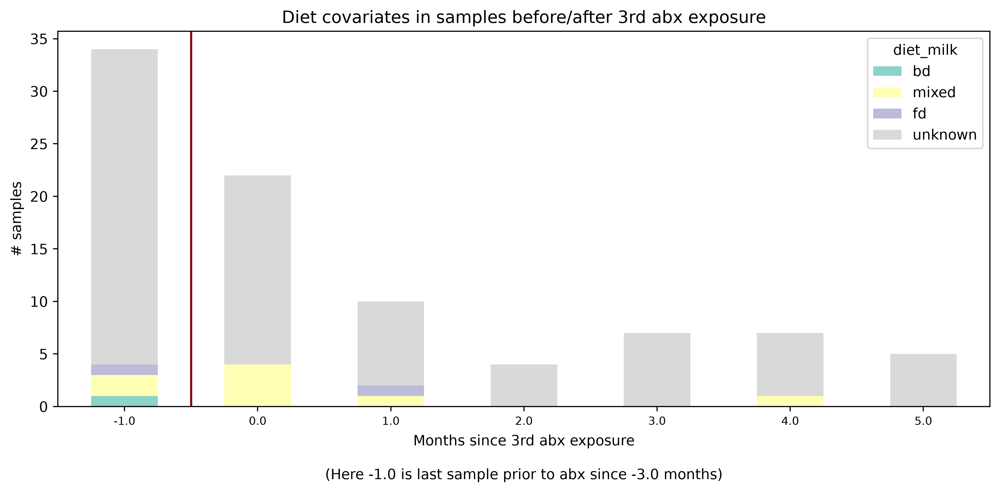

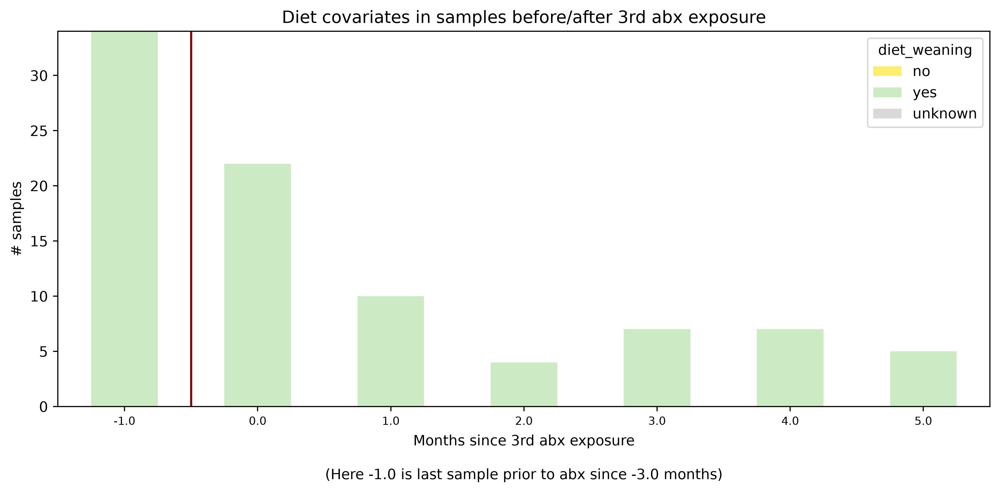

In [5]:
# get samples around n-th abx exposure
for n in [1, 2, 3]:
    score_col = f"score_{n}"
    scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
        abx_scores_flat,
        abx_df,
        n=n,
        min_samples=min_samples,
        max_samples=max_samples,
        group_samples=group_samples,
        score_var=score_col,
        max_resolution=max_resolution,
    )
    print(scores_abx_nth_samples.shape)
    _plot_score_after_nth_abx_exposure(
        scores_abx_nth_samples,
        x_axis="diff_age_nth_abx",
        y_axis=score_col,
        n=n,
        path_to_save=evaluation_path,
        flag=score_col,
        min_samples=min_samples,
        max_samples=max_samples,
        max_resolution=max_resolution,
        grouped_samples=group_samples,
    )

    if display_diet_info:
        suff = _get_ordinal_suffix(n)
        xlabel = f"Months since {n}{suff} abx exposure"
        if group_samples:
            if max_resolution:
                t1_reference = -0.5
            else:
                t1_reference = -1.0
            xlabel += f"\n\n(Here {t1_reference} is last sample prior "
            xlabel += f"to abx since {min_samples} months)"
        display_diet_information(
            scores_abx_nth_samples,
            "diet_milk",
            "diff_age_nth_abx",
            "samples",
            f"Diet covariates in samples before/after {n}{suff} abx exposure",
            x_axis=xlabel,
            path_to_save=evaluation_path,
        )
        display_diet_information(
            scores_abx_nth_samples,
            "diet_weaning",
            "diff_age_nth_abx",
            "samples",
            f"Diet covariates in samples before/after {n}{suff} abx exposure",
            x_axis=xlabel,
            path_to_save=evaluation_path,
        )

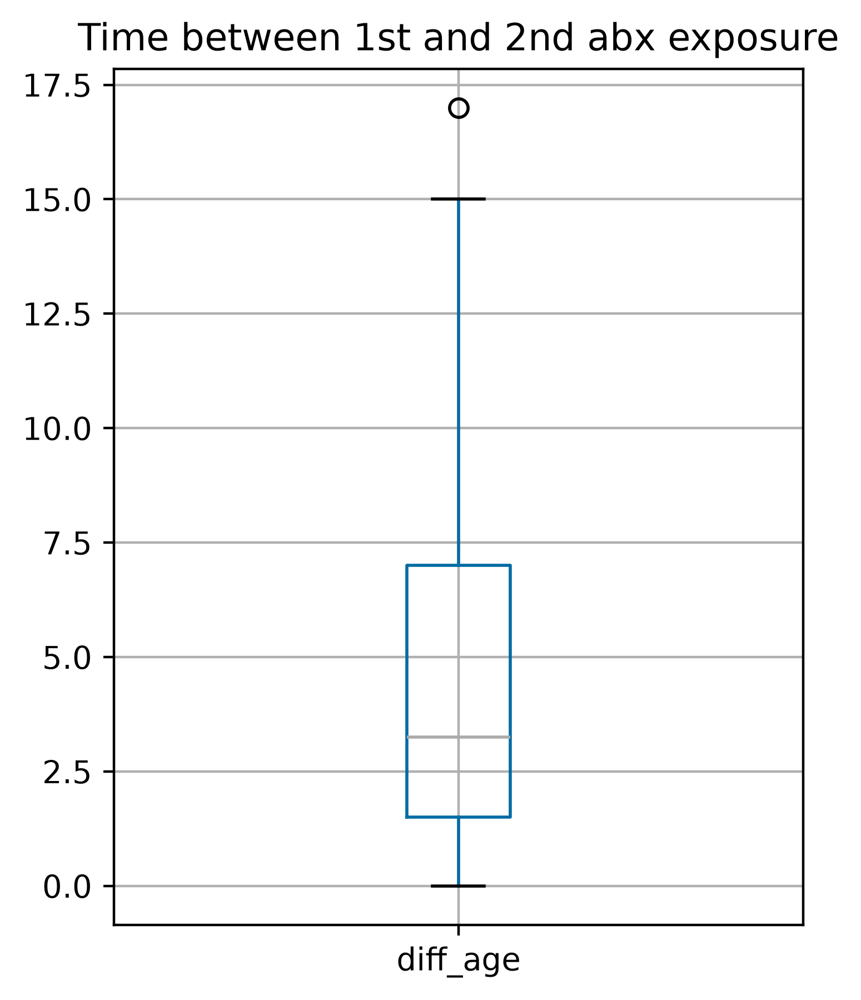

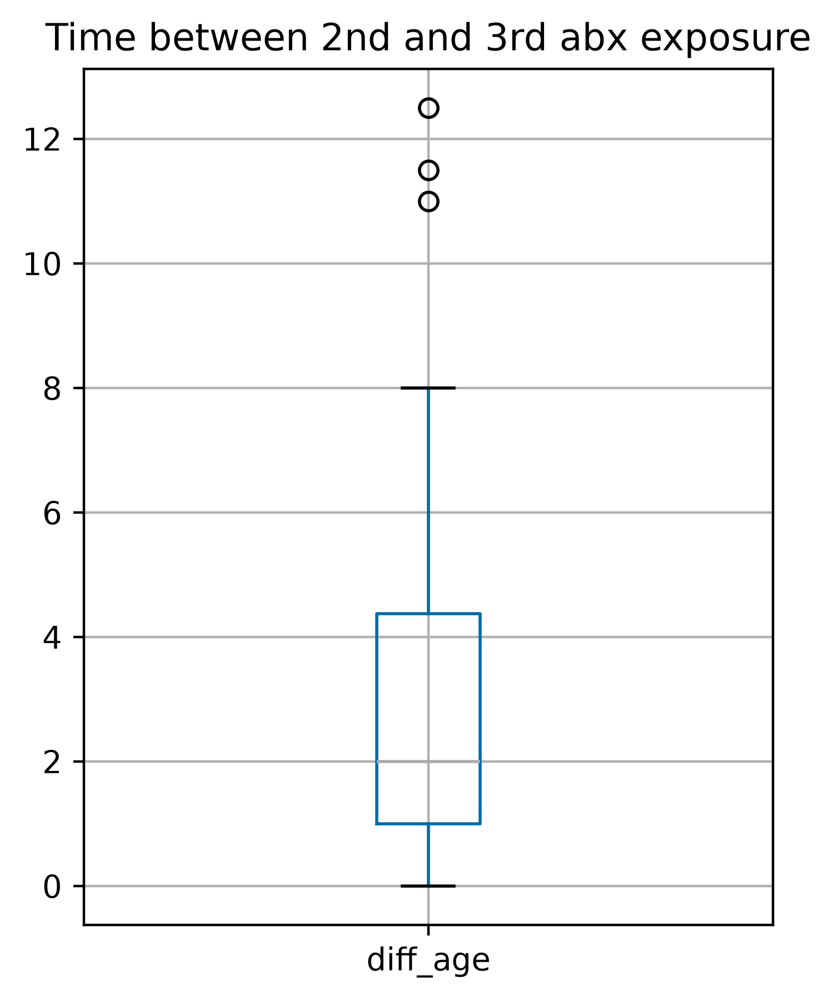

In [6]:
plot_time_between_abx_exposures(
    abx_age_at_all, n0_label="1st", n1_label="2nd", path_to_save=evaluation_path
)
plt.show()
plot_time_between_abx_exposures(
    abx_age_at_all, n0_label="2nd", n1_label="3rd", path_to_save=evaluation_path
)
plt.show()

Funfact: Here we compare hosts that have at least one sample prior or after the n-th abx exposure - so a sample that is directly influenced by the n-th exposure. This means concretely for n = 1:
* there are 141 hosts with a 1st abx exposure
* however, only 109 hosts are displayed in our plot with the filtering min_samples=-3, max_samples=6 and limit_months=24. 20 hosts are disregarded due to these filters. the remaining 12 hosts (see list below) have no samples prior or after the 1st abx exposure and are always excluded from these plots.

list of hosts with no sample before or directly affected by 1st abx exposure only: `['P003825', 'E002825', 'E007743', 'E014953', 'T029922', 'P010096', 'T000094', 'T000272', 'E012971', 'T028183', 'E016444', 'T007404']`

## Compare characteristics of 1st vs. 2nd vs. 3rd abx exposures

In [7]:
results = []
df_last_score = pd.DataFrame()

for n in [1, 2, 3]:
    score_col = f"score_{n}"
    scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
        abx_scores_flat,
        abx_df,
        n=n,
        min_samples=min_samples,
        max_samples=max_samples,
        group_samples=group_samples,
        score_var=score_col,
        max_resolution=max_resolution,
    )
    # number of unique infants exposed
    n_infants = scores_abx_nth_samples["host_id"].nunique()
    # Mean and std of abx duration
    abx_duration_desc = scores_abx_nth_samples["abx_any_last_dur_days"].describe()
    duration_mean = abx_duration_desc["mean"]
    duration_std = abx_duration_desc["std"]

    # Top x abx_type names
    abx_type_top = (
        scores_abx_nth_samples["abx_type"]
        .value_counts(dropna=False)
        .head(2)
        .index.tolist()
    )

    # Top x abx_reason names
    abx_reason_top = (
        scores_abx_nth_samples["abx_reason"]
        .value_counts(dropna=False)
        .head(2)
        .index.tolist()
    )

    # infant age at abx administration: age_nth_abx
    age_desc = scores_abx_nth_samples["age_nth_abx"].describe()

    # Collect results
    results.append(
        {
            "Cumcount abx exposure": n,
            # "nb_infants": n_infants,
            "age_mean": age_desc["mean"],
            "age_std": age_desc["std"],
            "abx_duration_days_mean": abx_duration_desc["mean"],
            "abx_duration_days_std": abx_duration_desc["std"],
            "abx_types_top2": abx_type_top,
            "abx_reasons_top2": abx_reason_top,
        }
    )

    # get last score prior to exposure
    df_last_score[n] = scores_abx_nth_samples.loc[
        scores_abx_nth_samples["diff_age_nth_abx"] == -1.0, f"score_{n}"
    ]

abx_stats_df = pd.DataFrame(results)
numeric_cols = [
    x for x in abx_stats_df.columns if x.endswith("_mean") or x.endswith("_std")
]
abx_stats_df[numeric_cols] = abx_stats_df[numeric_cols].round(2)
abx_stats_df

,Cumcount abx exposure,age_mean,age_std,abx_duration_days_mean,abx_duration_days_std,abx_types_top2,abx_reasons_top2
0,1,10.10,5.66,7.41,4.12,"[Penicillin, Other]","[Otitis media, Infection of respiratory tract]"
1,2,12.69,5.02,7.33,2.86,"[Penicillin, Other]","[Otitis media, Infection of respiratory tract]"
2,3,14.47,4.60,9.04,8.49,"[Penicillin, Macrolide]","[Otitis media, Infection of respiratory tract]"


Their abx characteristics are similar.

### Compare score distribution prior to exposure: 2nd vs. 3rd abx exposure

In [8]:
# compare 2nd vs. 3rd:
n2 = df_last_score[2].dropna()
n3 = df_last_score[3].dropna()
stat, p = mannwhitneyu(n2, n3, alternative="less")

print(p)

0.8624685039611204


## Score after 3rd abx: split by time since 2nd abx exposure


In [9]:
if not group_samples:
    duration_threshold = 4  # in months

    # perform grouping
    abx_time_between = abx_age_at_all.copy()
    abx_time_between["time_since_2nd"] = (
        abx_time_between["age_3rd_abx"] - abx_time_between["age_2nd_abx"]
    )

    bins = [-float("inf"), duration_threshold, float("inf")]
    between_labels = [
        f"<= {duration_threshold} months",
        f"> {duration_threshold} months",
    ]
    abx_time_between["time_since_2nd_cat"] = pd.cut(
        abx_time_between["time_since_2nd"],
        bins=bins,
        labels=between_labels,
        right=True,
    )
    abx_time_between.reset_index(inplace=True)

    # get samples around n-th abx exposure & plot
    n = 3
    i = 0
    score_col = f"score_{n}"
    scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
        abx_scores_flat,
        abx_df,
        n=n,
        min_samples=min_samples,
        max_samples=max_samples,
        group_samples=group_samples,
        score_var=score_col,
        max_resolution=max_resolution,
    )

    for cat in between_labels:
        # filter only for scores of hosts where 2nd abx is in cat time duration
        hosts = abx_time_between[abx_time_between["time_since_2nd_cat"] == cat][
            "host_id"
        ].unique()

        scores_abx_nth_samples_f = scores_abx_nth_samples[
            scores_abx_nth_samples["host_id"].isin(hosts)
        ].copy()
        flag = f"time_since_{n - 1}th_{i}"
        _plot_score_after_nth_abx_exposure(
            scores_abx_nth_samples_f,
            x_axis="diff_age_nth_abx",
            y_axis=score_col,
            n=n,
            path_to_save=evaluation_path,
            flag=flag,
            tag=f"time since {n - 1}nd abx exposure {cat}",
            min_samples=min_samples,
            max_samples=max_samples,
            max_resolution=max_resolution,
            grouped_samples=group_samples,
        )
        i += 1


## Score after 1st and 2nd abx

### split by abx characteristics

#### split by abx duration:

score_1
< 7 days
Number of unique infants: 39


Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_dur_0.pdf
>= 7 days


Number of unique infants: 51
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_dur_1.pdf


score_2
< 7 days
Number of unique infants: 31
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_dur_0.pdf


>= 7 days
Number of unique infants: 53
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_dur_1.pdf


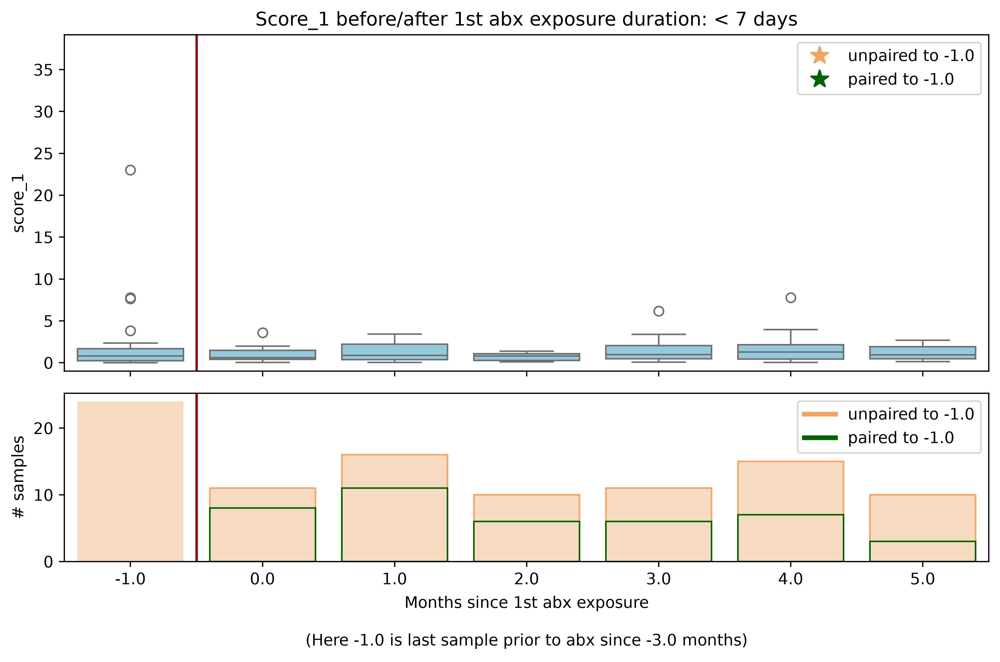

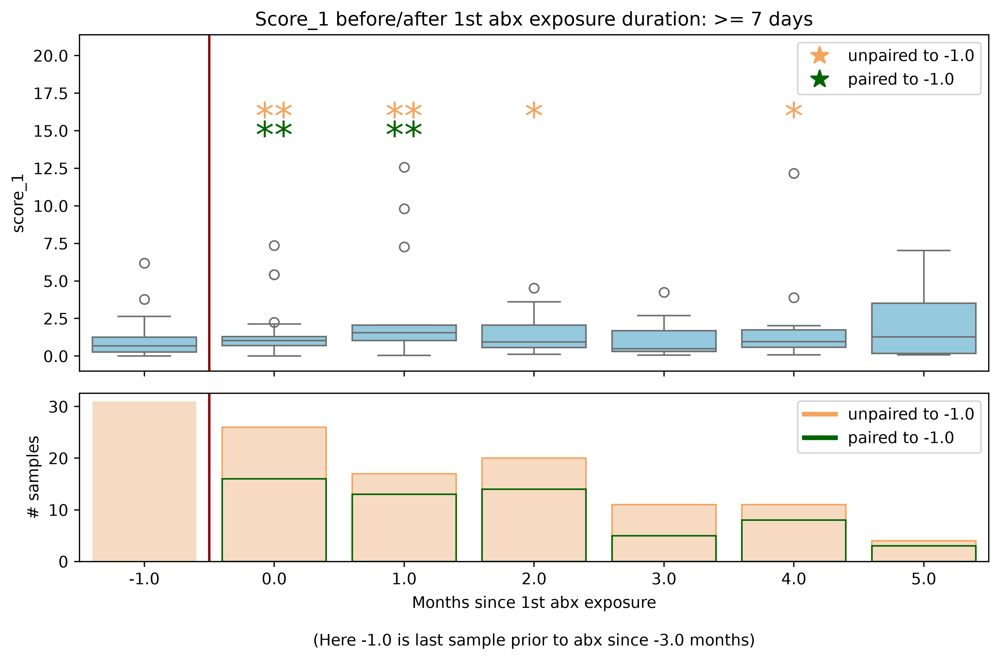

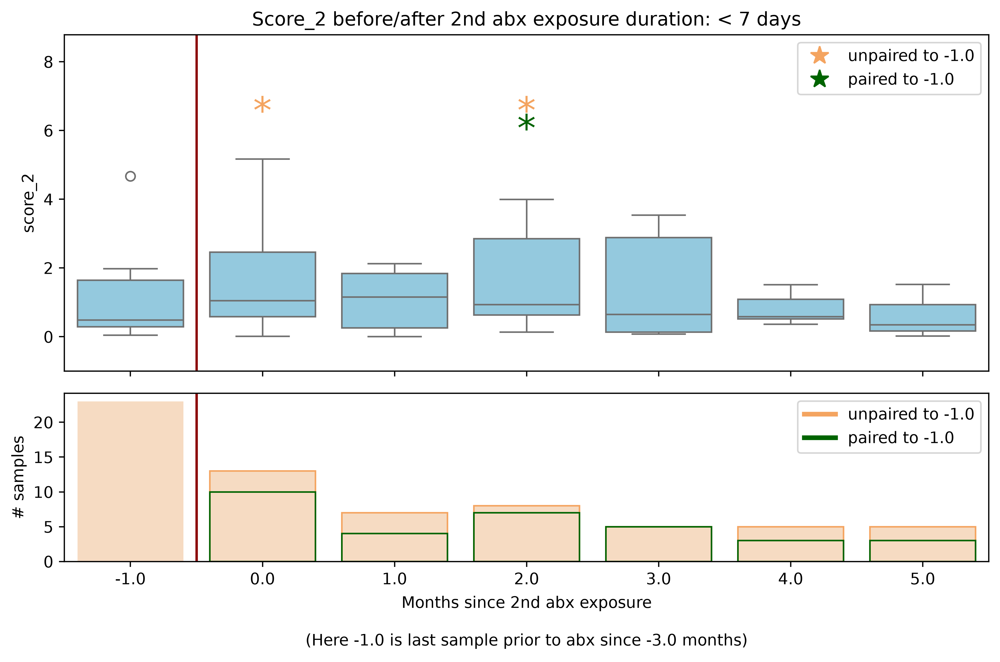

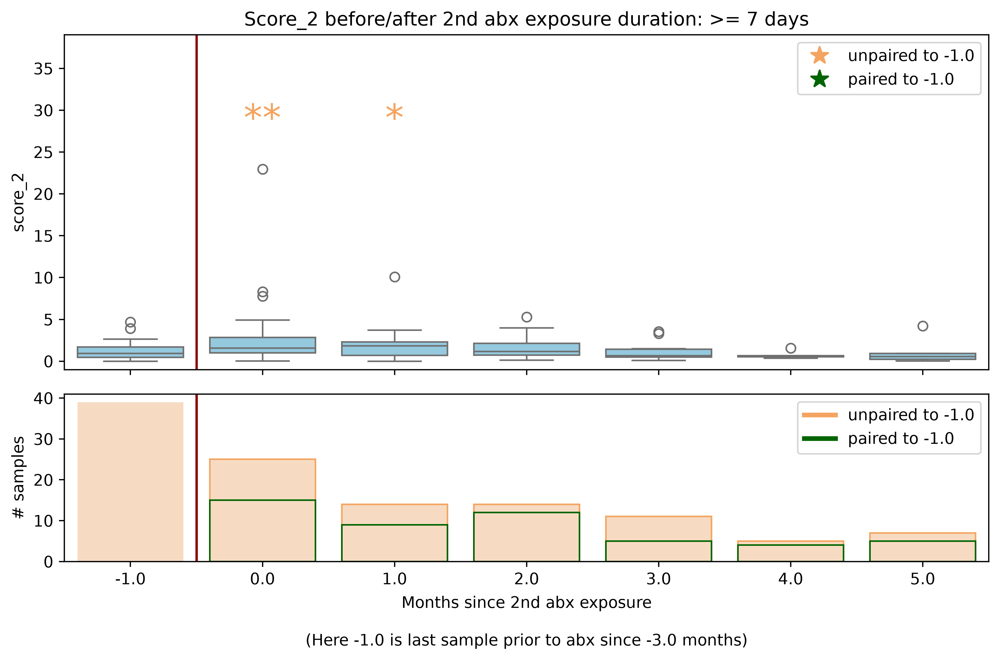

In [10]:
for n in [1, 2]:
    score_col = f"score_{n}"
    print(score_col)
    scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
        abx_scores_flat,
        abx_df,
        n=n,
        min_samples=min_samples,
        max_samples=max_samples,
        group_samples=group_samples,
        score_var=score_col,
        max_resolution=max_resolution,
    )

    # bin duration into short, mid and long duration
    # scores_abx_nth_samples["abx_any_last_dur_days"].hist(bins=10)

    bins = [-float("inf"), 7, float("inf")]
    dur_labels = ["< 7 days", ">= 7 days"]
    scores_abx_nth_samples["abx_duration_category"] = pd.cut(
        scores_abx_nth_samples["abx_any_last_dur_days"],
        bins=bins,
        labels=dur_labels,
        right=False,
    )

    # print(scores_abx_nth_samples["abx_duration_category"].value_counts(dropna=False))

    i = 0
    for dur in dur_labels:
        print(dur)
        # evaluation_path_bin = f"{evaluation_path}duration_bins{i}/"
        host_w_dur = (
            scores_abx_nth_samples.loc[
                scores_abx_nth_samples["abx_duration_category"] == dur, "host_id"
            ]
            .unique()
            .tolist()
        )
        scores_abx_nth_samples_dur = scores_abx_nth_samples.loc[
            scores_abx_nth_samples["host_id"].isin(host_w_dur)
        ].copy()
        flag_dur = f"dur_{i}"
        print(
            f"Number of unique infants: {scores_abx_nth_samples_dur['host_id'].nunique()}"
        )
        _plot_score_after_nth_abx_exposure(
            scores_abx_nth_samples_dur,
            x_axis="diff_age_nth_abx",
            y_axis=score_col,
            n=n,
            path_to_save=evaluation_path,
            flag=flag_dur,
            tag=f"duration: {dur}",
            min_samples=min_samples,
            max_samples=max_samples,
            max_resolution=max_resolution,
            grouped_samples=group_samples,
        )

        i += 1

#### split by type of abx (top 1 vs. others) - only n=1

In [11]:
n = 2
score_col = f"score_{n}"
scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
    abx_scores_flat,
    abx_df,
    n=n,
    min_samples=min_samples,
    max_samples=max_samples,
    group_samples=group_samples,
    score_var=score_col,
    max_resolution=max_resolution,
)


In [12]:
scores_abx_nth_samples["abx_type"].value_counts(dropna=False)

abx_type
Penicillin                                   46
Other                                        32
Cephalosporine                               26
Cotrimoxazole                                18
Macrolide                                     9
Cephalosporine, Macrolide                     6
Cotrimoxazole, Penicillin                     4
Other, Penicillin                             2
Cephalosporine, Penicillin                    2
Cephalosporine, Cotrimoxazole, Penicillin     1
Macrolide, Other                              1
Cephalosporine, Cotrimoxazole                 1
Name: count, dtype: int64

In [13]:
# add top 1 vs. others
scores_abx_nth_samples["abx_type_cat"] = scores_abx_nth_samples["abx_type"].apply(
    lambda x: "Penicillin" if x == "Penicillin" else "Others"
)
scores_abx_nth_samples["abx_type_cat"].value_counts(dropna=False)

abx_type_cat
Others        102
Penicillin     46
Name: count, dtype: int64

In [14]:
# select types to look for
abx_types = scores_abx_nth_samples["abx_type_cat"].unique().tolist()
# abx_types = ["Penicillin", "Cephalosporine", "Cotrimoxazole", "Macrolide"]
abx_types

['Others', 'Penicillin']

Others
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_abx_type_others.pdf


Penicillin
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_abx_type_penicillin.pdf


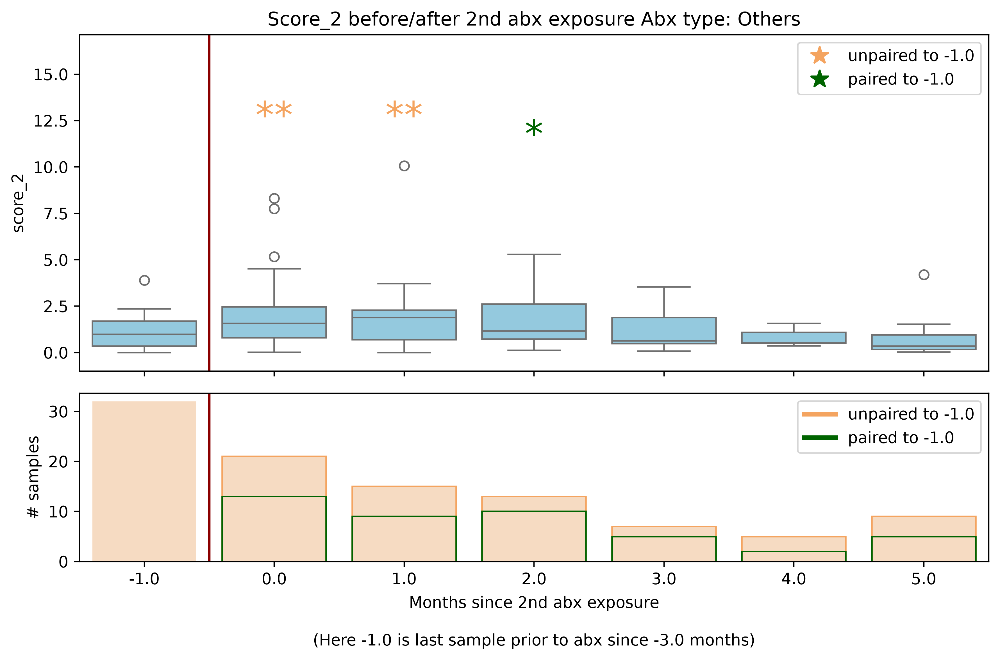

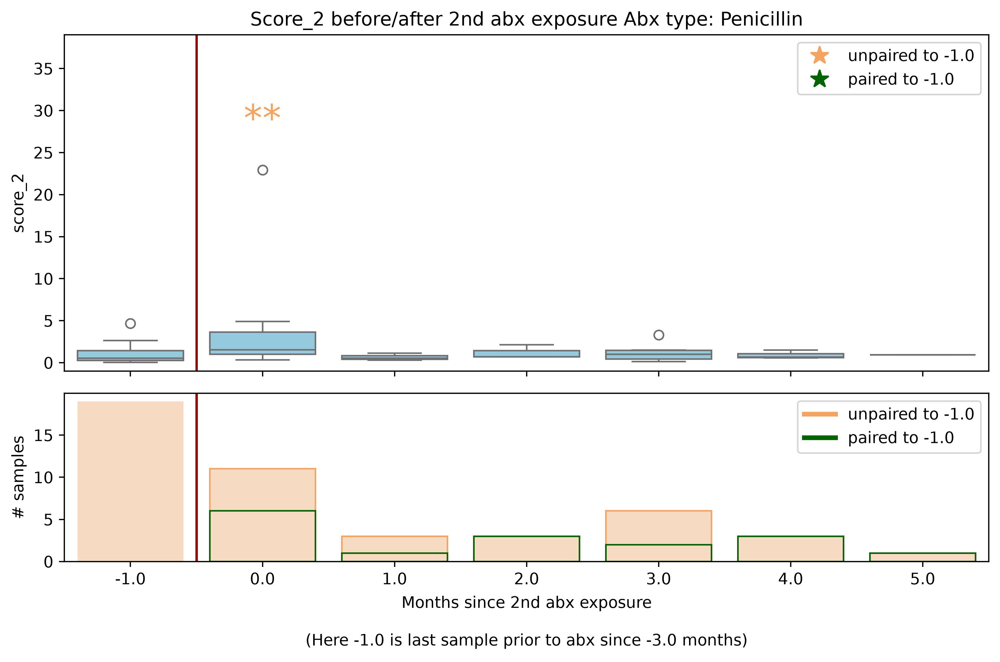

In [15]:
abx_col = "abx_type_cat"
# abx_col = "abx_type"
for abx in abx_types:
    print(abx)
    abx_str = abx.lower().replace(" ", "_").replace(",", "_")
    flag_abx = f"abx_type_{abx_str}"
    # evaluation_path_abx = f"{evaluation_path}abx_type_{abx_str}/"

    # age at time of abx exposure should match a
    scores_abx_nth_samples_abx = scores_abx_nth_samples.loc[
        scores_abx_nth_samples[abx_col].str.contains(abx)
    ].copy()

    _plot_score_after_nth_abx_exposure(
        scores_abx_nth_samples_abx,
        x_axis="diff_age_nth_abx",
        y_axis=score_col,
        n=n,
        path_to_save=evaluation_path,
        flag=flag_abx,
        tag=f"Abx type: {abx}",
        min_samples=min_samples,
        max_samples=max_samples,
        max_resolution=max_resolution,
        grouped_samples=group_samples,
    )

    i += 1

#### split by type of abx reason (top 1 vs. others) - only n=1

In [16]:
n = 1
score_col = f"score_{n}"
scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
    abx_scores_flat,
    abx_df,
    n=n,
    min_samples=min_samples,
    max_samples=max_samples,
    group_samples=group_samples,
    score_var=score_col,
    max_resolution=max_resolution,
)
# top 1 vs. others
print(scores_abx_nth_samples["abx_reason"].value_counts(dropna=False))

# scores_abx_nth_samples["abx_reason_cat"] = scores_abx_nth_samples["abx_reason"].apply(
#     lambda x: "Otitis media" if x == "Otitis media" else "Others"
# )

scores_abx_nth_samples["abx_reason_cat"] = scores_abx_nth_samples["abx_reason"].apply(
    lambda x: "Gastroenteritis" if x == "Gastroenteritis" else "Not Gastroenteritis"
)

print(scores_abx_nth_samples["abx_reason_cat"].value_counts(dropna=False))

reasons = scores_abx_nth_samples["abx_reason_cat"].unique().tolist()


abx_reason
Otitis media                                    138
Infection of respiratory tract                   39
Others                                           27
Gastroenteritis                                  18
Infection of urinary tract                        7
Prophylaxis                                       4
Infection of respiratory tract, Otitis media      2
Infection in neonatal period                      1
Name: count, dtype: int64
abx_reason_cat
Not Gastroenteritis    218
Gastroenteritis         18
Name: count, dtype: int64


In [17]:
# # top 4 reasons
# reasons = (
#     scores_abx_nth_samples["abx_reason"]
#     .value_counts(dropna=False)
#     .iloc[:4]
#     .index.tolist()
# )
# reasons

Not Gastroenteritis


Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_abx_reason_not_gastroenteritis.pdf
Gastroenteritis


Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_abx_reason_gastroenteritis.pdf


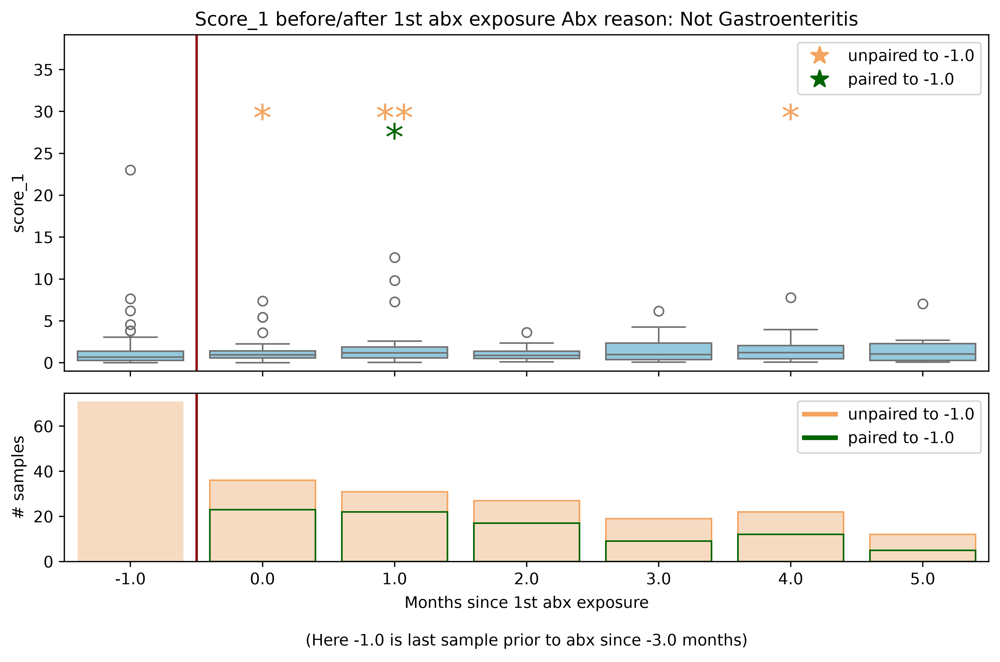

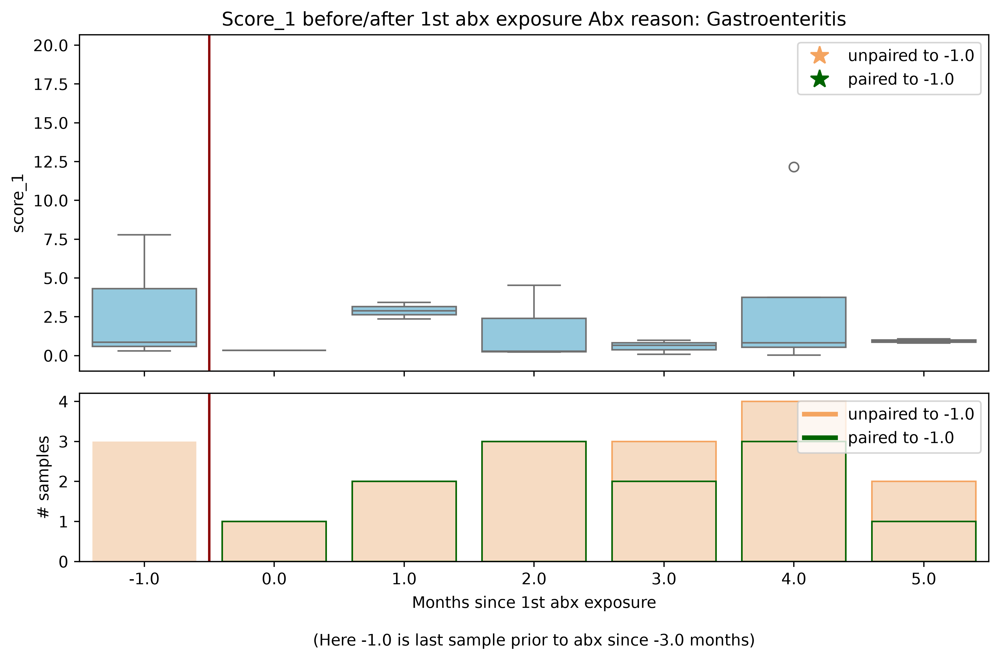

In [18]:
for r in reasons:
    print(r)
    r_str = r.lower().replace(" ", "_").replace(",", "_")
    # evaluation_path_r = f"{evaluation_path}abx_reason_{r_str}/"

    # age at time of abx exposure should match a
    scores_abx_nth_samples_r = scores_abx_nth_samples.loc[
        scores_abx_nth_samples["abx_reason_cat"] == r
    ].copy()
    flag_reason = f"abx_reason_{r_str}"
    _plot_score_after_nth_abx_exposure(
        scores_abx_nth_samples_r,
        x_axis="diff_age_nth_abx",
        y_axis=score_col,
        n=n,
        path_to_save=evaluation_path,
        flag=flag_reason,
        tag=f"Abx reason: {r}",
        min_samples=min_samples,
        max_samples=max_samples,
        max_resolution=max_resolution,
        grouped_samples=group_samples,
    )

    i += 1

### split by host characteristics

#### split by time of life:

score_1
age_nth_abx_category
<= 12 months      161
12 - 24 months     75
Name: count, dtype: int64
<= 12 months
Number of unique infants: 75
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_age_0.pdf


12 - 24 months
Number of unique infants: 34
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_age_1.pdf


score_2
age_nth_abx_category
<= 12 months      74
12 - 24 months    74
Name: count, dtype: int64
<= 12 months
Number of unique infants: 35
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_age_0.pdf


12 - 24 months
Number of unique infants: 38
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx2nd_age_1.pdf


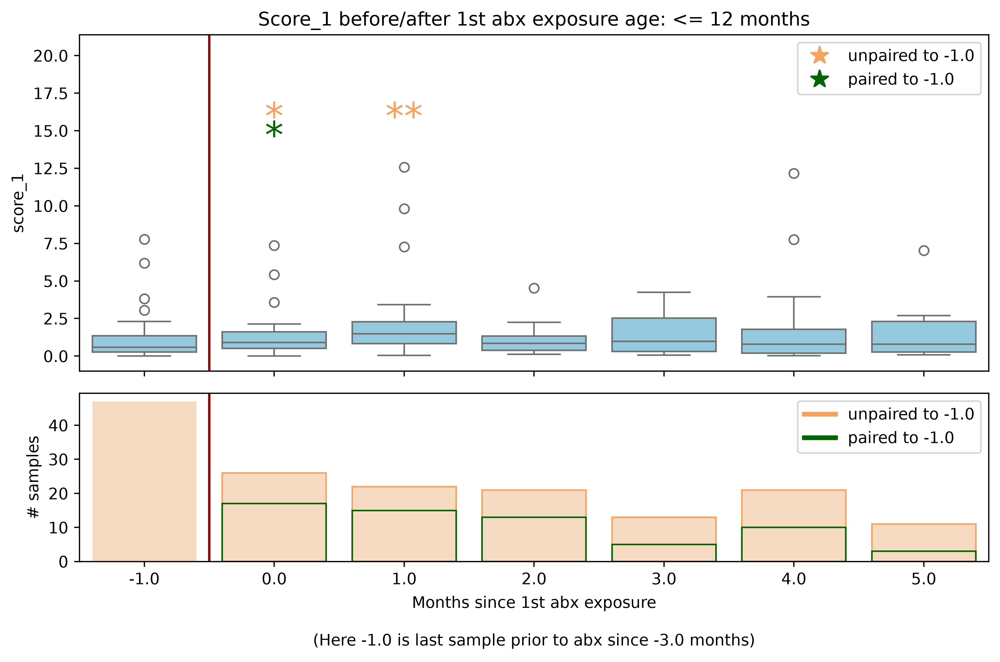

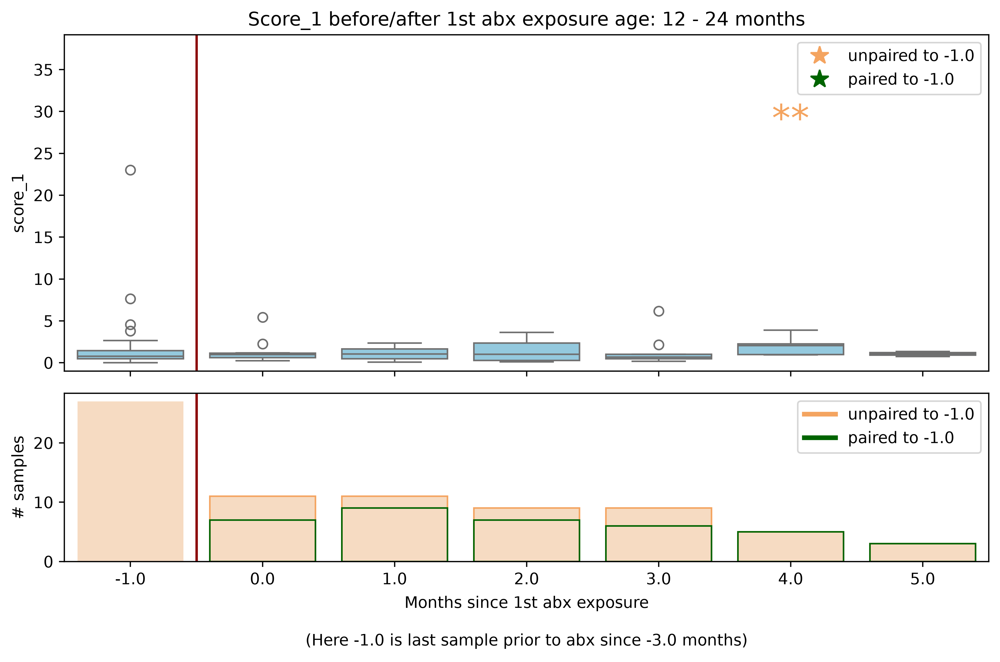

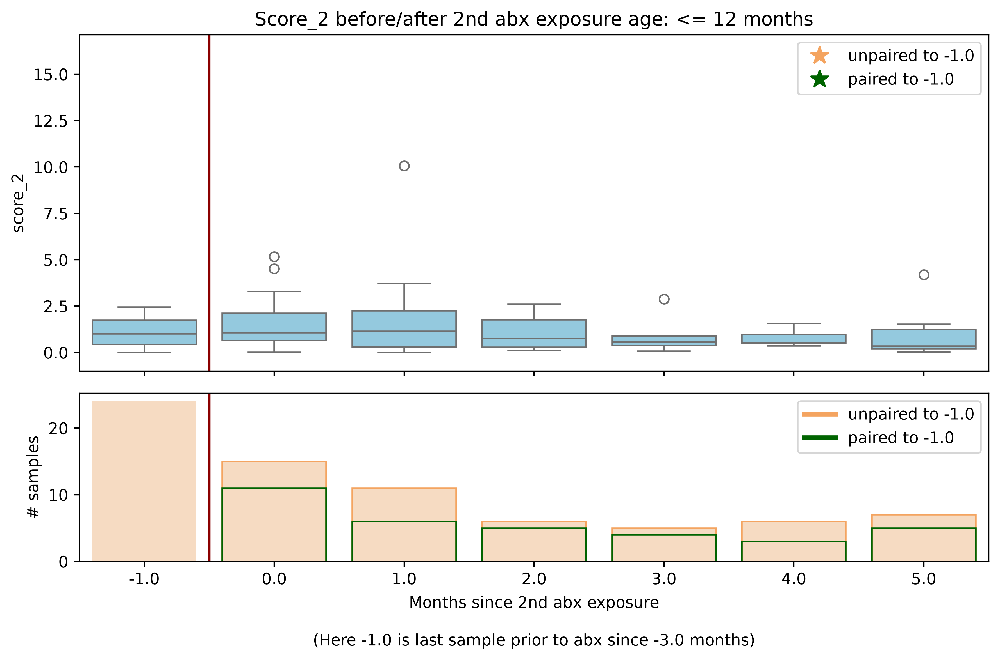

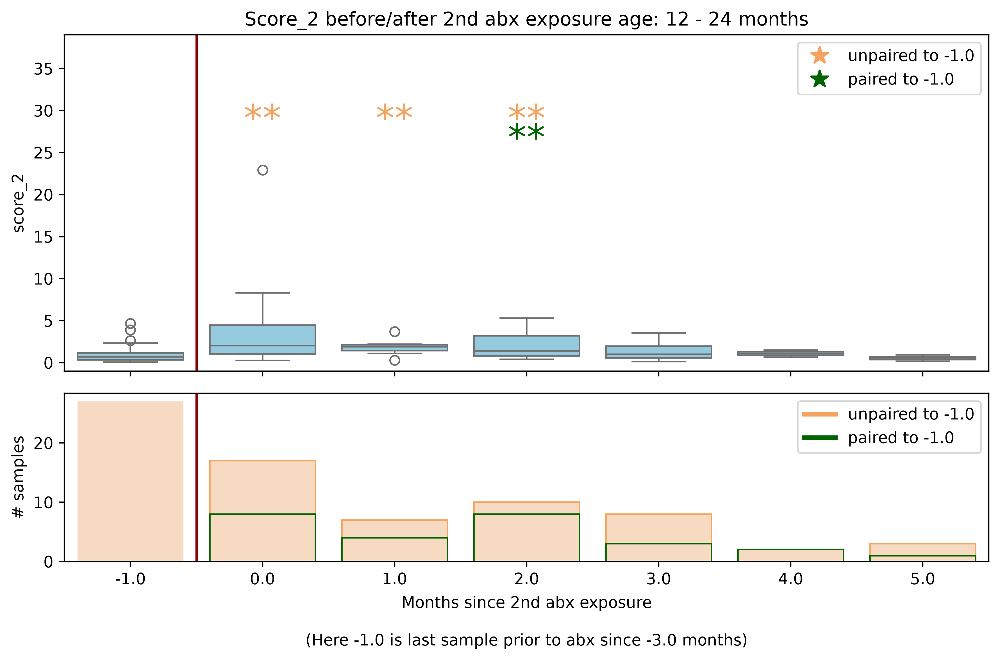

In [19]:
for n in [1, 2]:
    score_col = f"score_{n}"
    print(score_col)
    scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
        abx_scores_flat,
        abx_df,
        n=n,
        min_samples=min_samples,
        max_samples=max_samples,
        group_samples=group_samples,
        score_var=score_col,
        max_resolution=max_resolution,
    )

    # bin age
    # scores_abx_nth_samples["age_nth_abx"].hist(bins=24)

    bins_age = [-float("inf"), 12, float("inf")]
    # <6: pre weaning
    age_labels = ["<= 12 months", "12 - 24 months"]
    scores_abx_nth_samples["age_nth_abx_category"] = pd.cut(
        scores_abx_nth_samples["age_nth_abx"],
        bins=bins_age,
        labels=age_labels,
        right=True,
    )
    print(scores_abx_nth_samples["age_nth_abx_category"].value_counts(dropna=False))

    i = 0
    for a in age_labels:
        print(a)
        # evaluation_path_bin = f"{evaluation_path}age_bins{i}/"
        # age at time of abx exposure should match a
        scores_abx_nth_samples_age = scores_abx_nth_samples.loc[
            scores_abx_nth_samples["age_nth_abx_category"] == a
        ].copy()
        flag_age = f"age_{i}"
        print(
            f"Number of unique infants: {scores_abx_nth_samples_age['host_id'].nunique()}"
        )
        _plot_score_after_nth_abx_exposure(
            scores_abx_nth_samples_age,
            x_axis="diff_age_nth_abx",
            y_axis=score_col,
            n=n,
            path_to_save=evaluation_path,
            flag=flag_age,
            tag=f"age: {a}",
            min_samples=min_samples,
            max_samples=max_samples,
            max_resolution=max_resolution,
            grouped_samples=group_samples,
        )

        i += 1

split by time of life & then diet_milk:

score_1
age_nth_abx_category
<= 12 months      161
12 - 24 months     75
Name: count, dtype: int64
<= 12 months
['mixed', 'bd']
Number of unique infants: 44


<= 12 months
['fd']
Number of unique infants: 12
12 - 24 months
['mixed', 'bd']
Number of unique infants: 4


12 - 24 months
['fd']
Number of unique infants: 0
score_2
age_nth_abx_category
<= 12 months      74
12 - 24 months    74
Name: count, dtype: int64
<= 12 months
['mixed', 'bd']
Number of unique infants: 16
<= 12 months
['fd']
Number of unique infants: 5


12 - 24 months
['mixed', 'bd']
Number of unique infants: 4
12 - 24 months
['fd']
Number of unique infants: 0


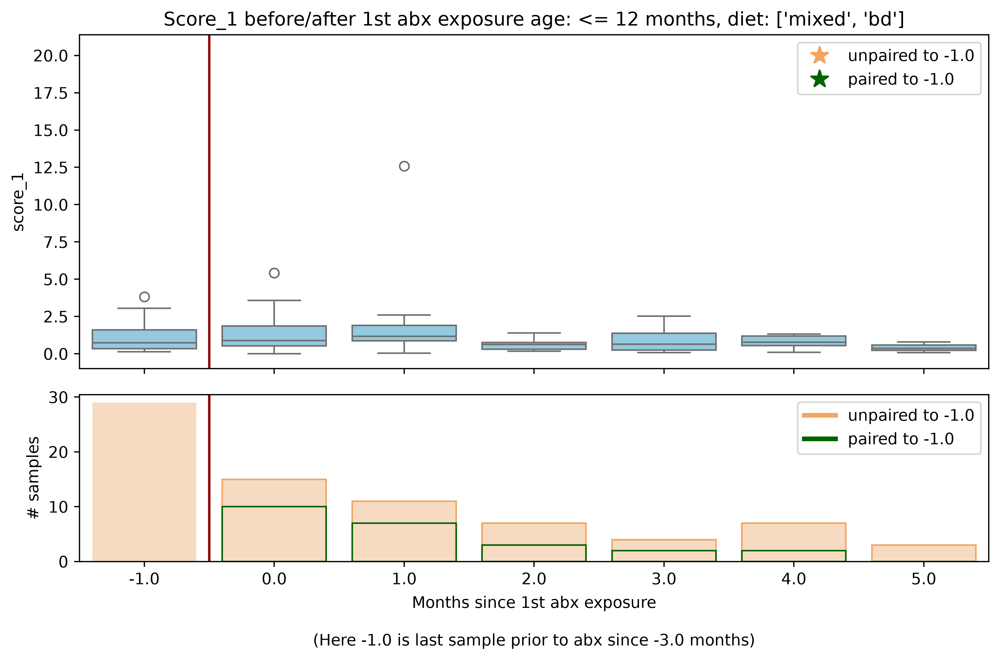

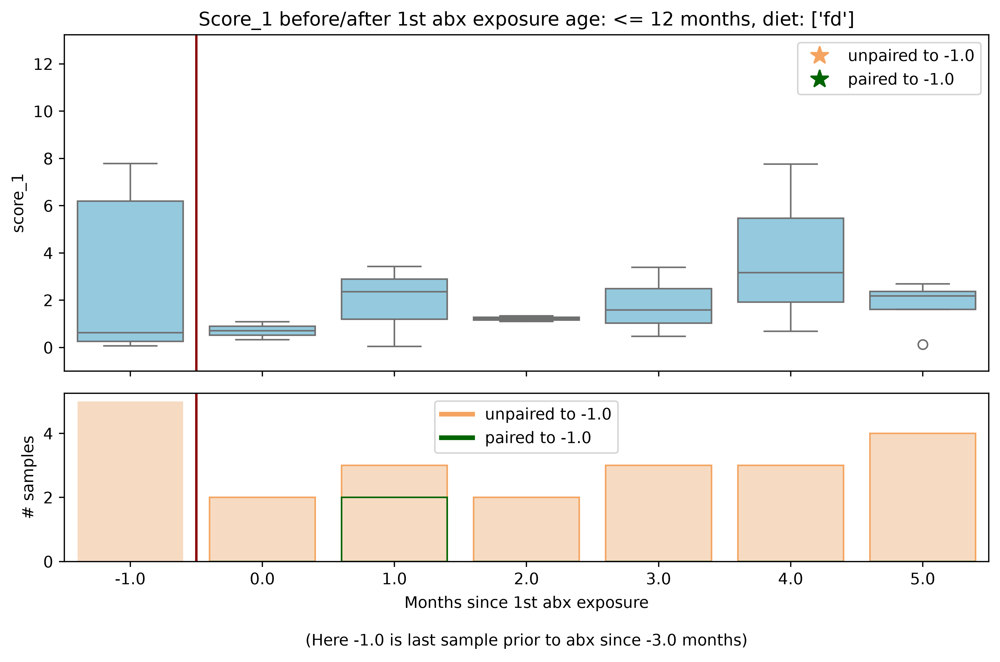

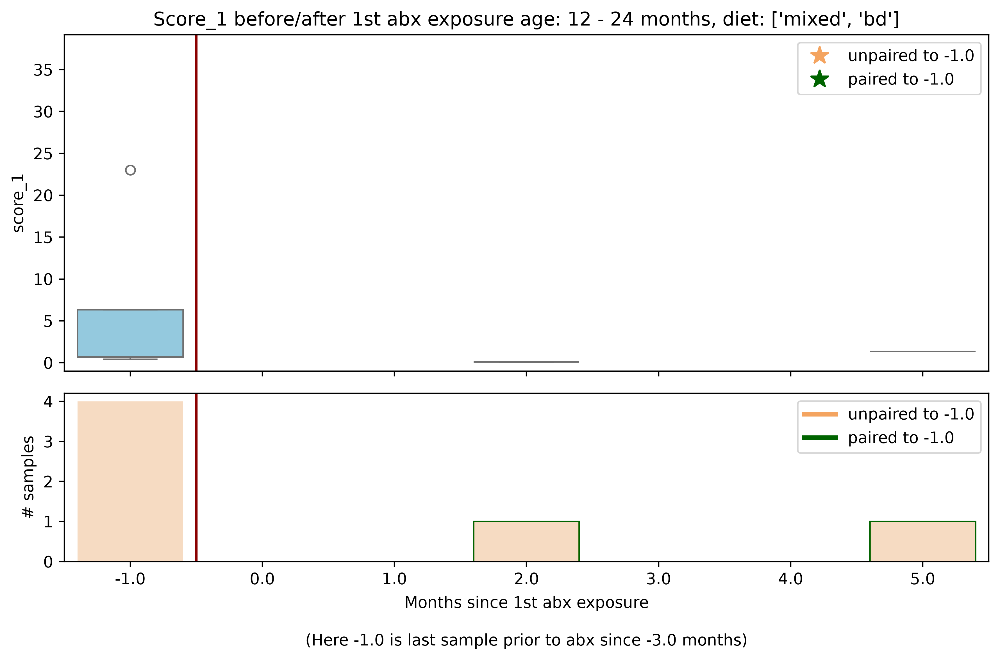

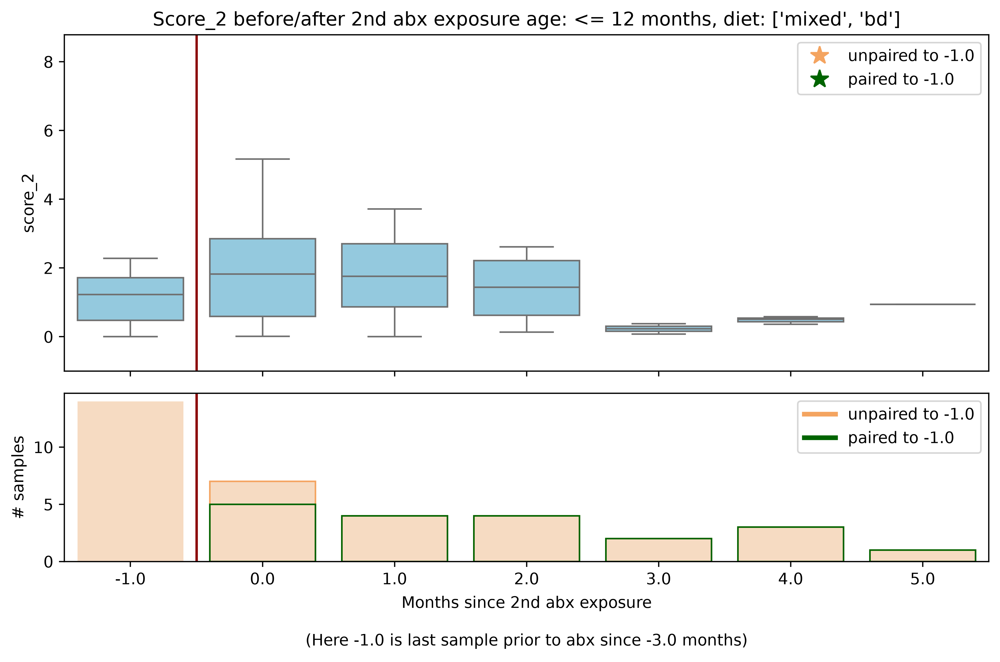

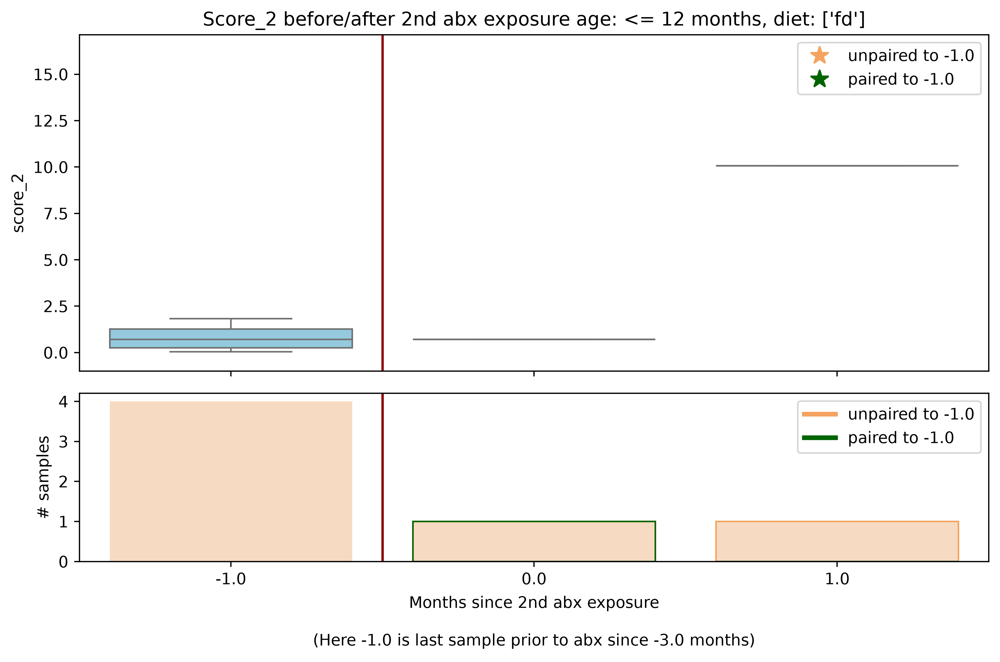

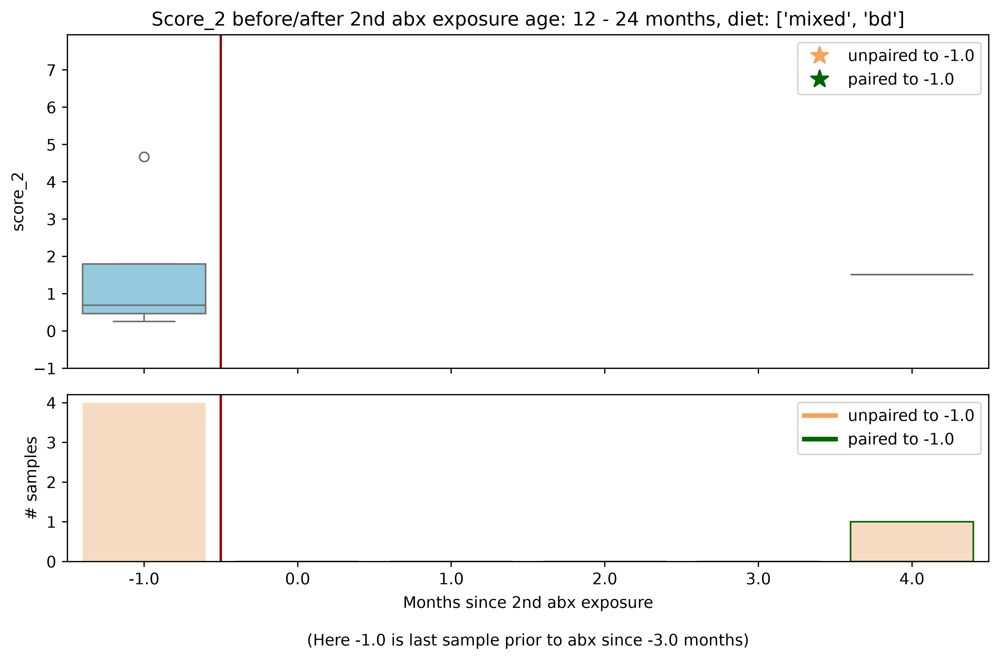

In [20]:
for n in [1, 2]:
    score_col = f"score_{n}"
    print(score_col)
    scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
        abx_scores_flat,
        abx_df,
        n=n,
        min_samples=min_samples,
        max_samples=max_samples,
        group_samples=group_samples,
        score_var=score_col,
        max_resolution=max_resolution,
    )

    # bin age
    # scores_abx_nth_samples["age_nth_abx"].hist(bins=24)

    bins_age = [-float("inf"), 12, float("inf")]
    # <6: pre weaning
    age_labels = ["<= 12 months", "12 - 24 months"]
    scores_abx_nth_samples["age_nth_abx_category"] = pd.cut(
        scores_abx_nth_samples["age_nth_abx"],
        bins=bins_age,
        labels=age_labels,
        right=True,
    )
    print(scores_abx_nth_samples["age_nth_abx_category"].value_counts(dropna=False))

    for a in age_labels:
        for b in [["mixed", "bd"], ["fd"]]:
            print(a)
            print(b)
            # evaluation_path_bin = f"{evaluation_path}age_bins{i}/"
            # age at time of abx exposure should match a
            scores_abx_nth_samples_age = scores_abx_nth_samples.loc[
                scores_abx_nth_samples["age_nth_abx_category"] == a
            ].copy()
            scores_abx_nth_samples_age_n_diet = scores_abx_nth_samples_age.loc[
                scores_abx_nth_samples_age["diet_milk"].isin(b)
            ].copy()
            flag_age_n_diet = f"age_{i}"

            nb_infants = scores_abx_nth_samples_age_n_diet["host_id"].nunique()
            print(f"Number of unique infants: {nb_infants}")
            if nb_infants != 0:
                _plot_score_after_nth_abx_exposure(
                    scores_abx_nth_samples_age_n_diet,
                    x_axis="diff_age_nth_abx",
                    y_axis=score_col,
                    n=n,
                    path_to_save=None,
                    flag=flag_age_n_diet,
                    tag=f"age: {a}, diet: {b}",
                    min_samples=min_samples,
                    max_samples=max_samples,
                    max_resolution=max_resolution,
                    grouped_samples=group_samples,
                )


#### split by delivery mode:

vaginal


Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_delivery_vaginal.pdf


cesarean
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_delivery_cesarean.pdf


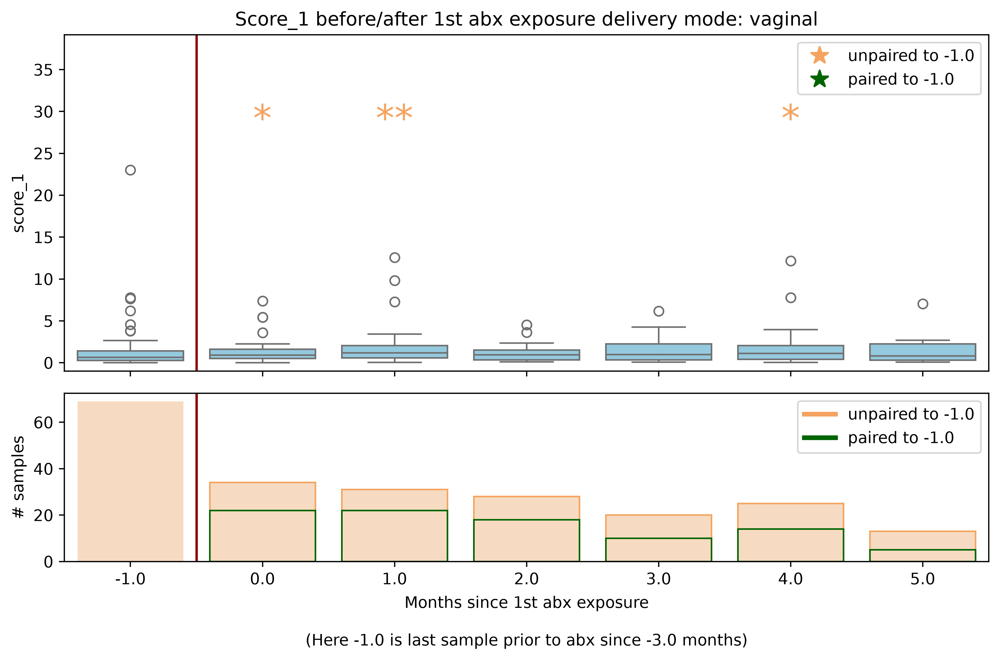

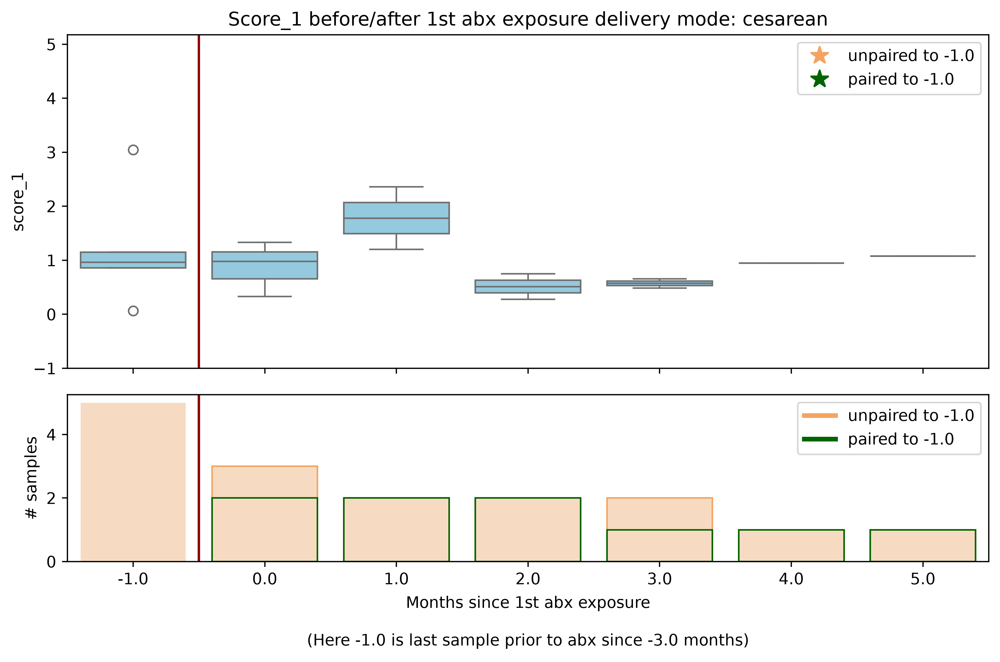

In [21]:
n = 1
score_col = f"score_{n}"
scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
    abx_scores_flat,
    abx_df,
    n=n,
    min_samples=min_samples,
    max_samples=max_samples,
    group_samples=group_samples,
    score_var=score_col,
    max_resolution=max_resolution,
)

delivery_labels = scores_abx_nth_samples.delivery_mode.unique().tolist()

i = 0
for a in delivery_labels:
    print(a)
    scores_abx_nth_samples_delivery = scores_abx_nth_samples.loc[
        scores_abx_nth_samples["delivery_mode"] == a
    ].copy()

    flag_delivery = f"delivery_{a}"

    _plot_score_after_nth_abx_exposure(
        scores_abx_nth_samples_delivery,
        x_axis="diff_age_nth_abx",
        y_axis=score_col,
        n=n,
        path_to_save=evaluation_path,
        flag=flag_delivery,
        tag=f"delivery mode: {a}",
        min_samples=min_samples,
        max_samples=max_samples,
        max_resolution=max_resolution,
        grouped_samples=group_samples,
    )

    i += 1

#### split by feeding mode:

mixed
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_diet_mixed.pdf


None
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_diet_None.pdf


bd
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_diet_bd.pdf


fd
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_diet_fd.pdf


yes
Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_diet_yes.pdf


no


Saving plot to ../data/saved_models_microbial_novel_alpha_div_shannon/id-1/anomaly_detection/evaluation_best_overall_gT_maxresF_nc_std_ma10__rd_true/score_after_abx1st_diet_no.pdf


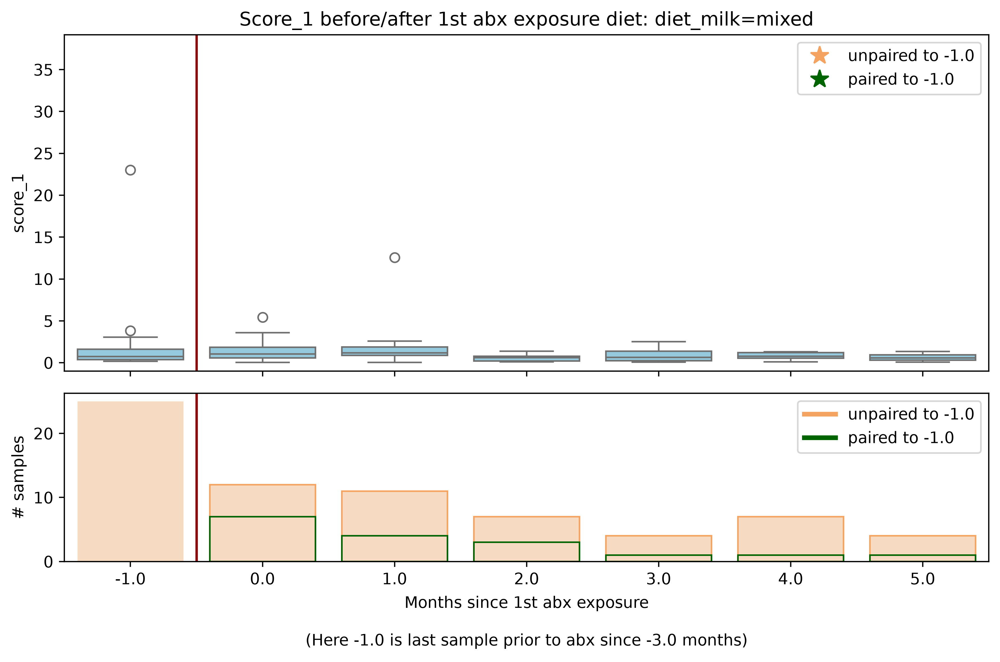

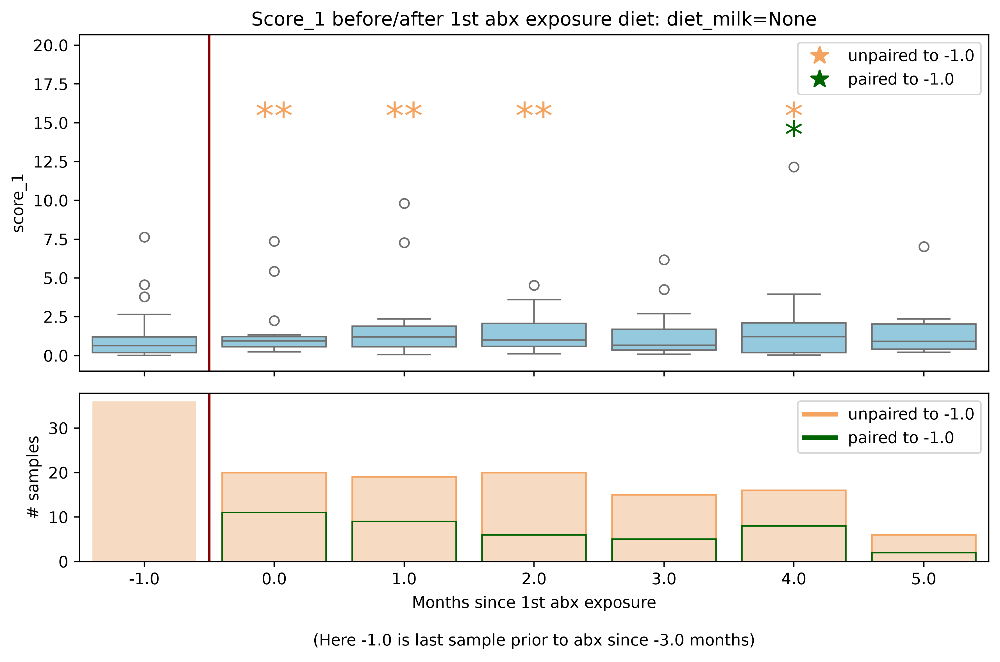

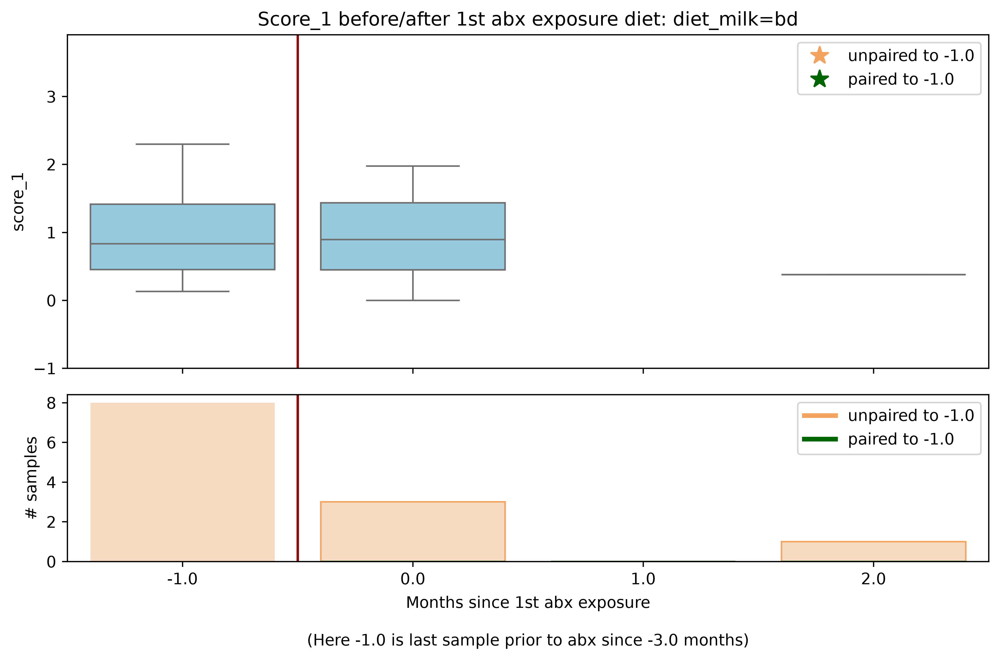

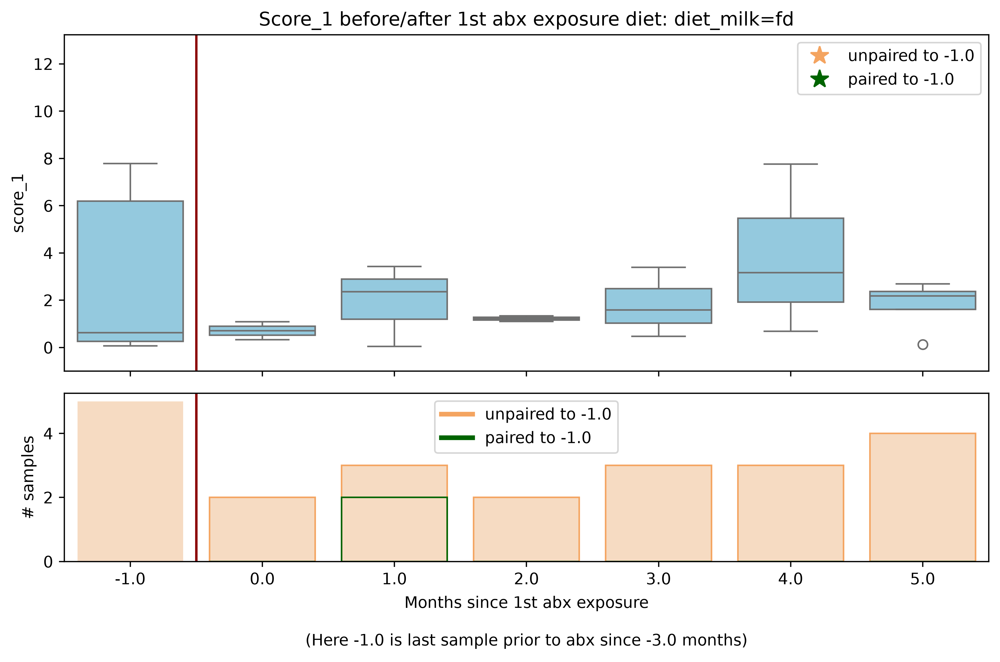

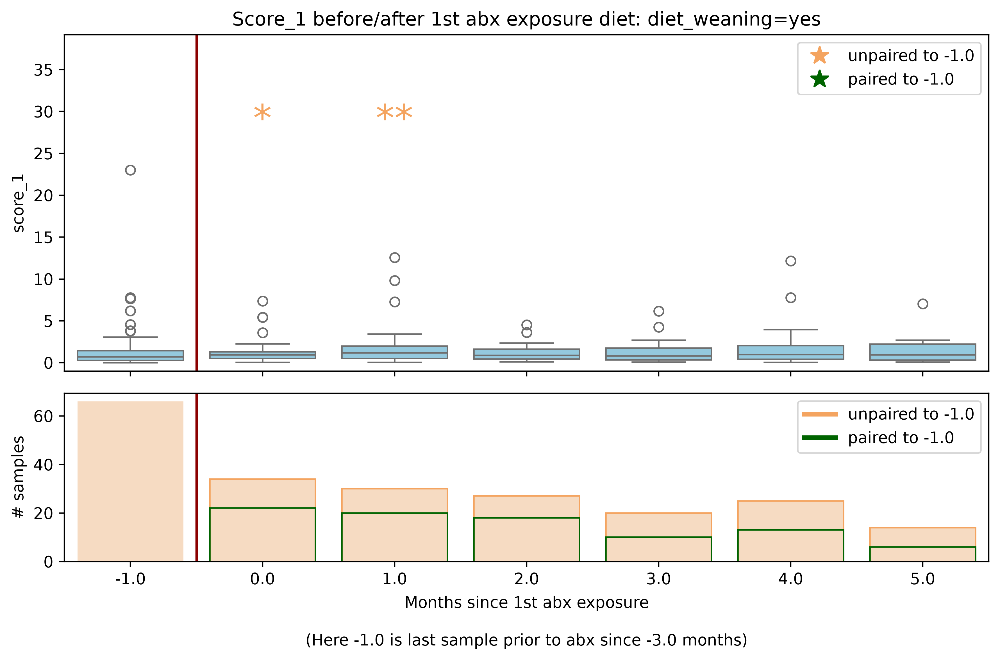

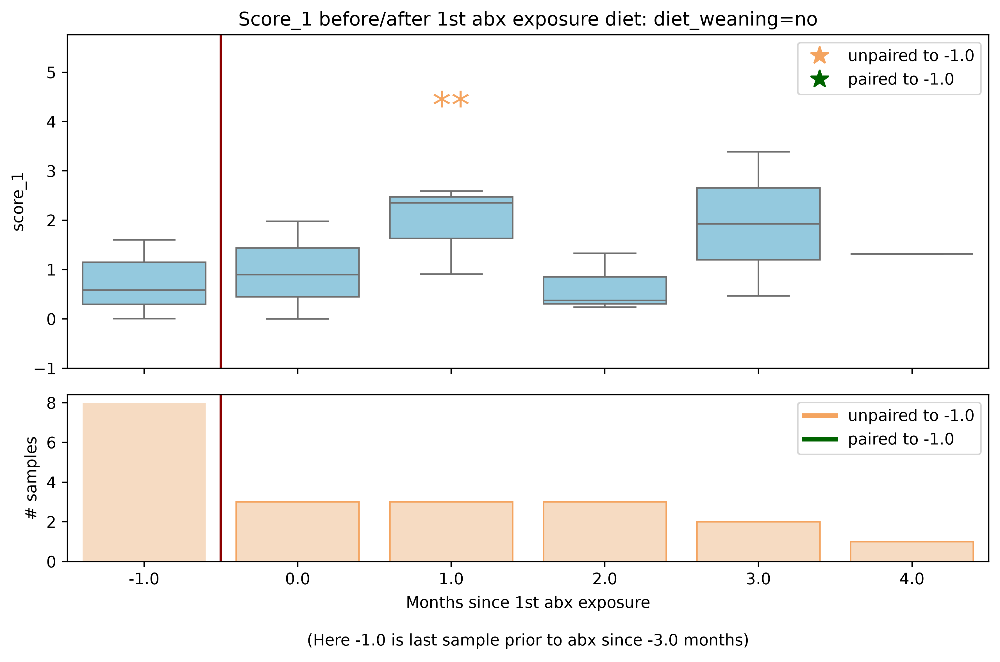

In [22]:
n = 1
score_col = f"score_{n}"
scores_abx_nth_samples = _select_samples_around_nth_abx_exposure(
    abx_scores_flat,
    abx_df,
    n=n,
    min_samples=min_samples,
    max_samples=max_samples,
    group_samples=group_samples,
    score_var=score_col,
    max_resolution=max_resolution,
)

for diet_col in ["diet_milk", "diet_weaning"]:
    diet_labels = scores_abx_nth_samples[diet_col].unique().tolist()

    i = 0
    for a in diet_labels:
        print(a)
        scores_abx_nth_samples_diet = scores_abx_nth_samples.loc[
            scores_abx_nth_samples[diet_col] == a
        ].copy()

        if a is None:
            scores_abx_nth_samples_diet = scores_abx_nth_samples.loc[
                scores_abx_nth_samples[diet_col].isna()
            ].copy()

        flag_diet = f"diet_{a}"

        _plot_score_after_nth_abx_exposure(
            scores_abx_nth_samples_diet,
            x_axis="diff_age_nth_abx",
            y_axis=score_col,
            n=n,
            path_to_save=evaluation_path,
            flag=flag_diet,
            tag=f"diet: {diet_col}={a}",
            min_samples=min_samples,
            max_samples=max_samples,
            max_resolution=max_resolution,
            grouped_samples=group_samples,
        )

        i += 1

## Score over age range

In [23]:
dic_splits_n_scores = {
    "train_noabx": ["score_1", noabx_train, None],
    "val_noabx": ["score_1", noabx_val, None],
    "abx_1st": ["score_1", abx_scores_flat, abx_age_at_all["age_1st_abx"]],
    "abx_2nd": ["score_2", abx_scores_flat, abx_age_at_all["age_2nd_abx"]],
    "abx_3rd": ["score_3", abx_scores_flat, abx_age_at_all["age_3rd_abx"]],
}

for name, v in dic_splits_n_scores.items():
    score_col = v[0]
    scores = v[1]
    abx_age_values = v[2]
    _plot_score_over_age(scores, score_col, name, evaluation_path, abx_age_values)
    plt.show()

## Score overall - scatter

In [24]:
# sort both abx dataframes by increasing abx exposure in same way
abx_scores_flat.sort_values(
    [
        "abx_max_count_ever",
        "max_abx_w_microbiome",
        "host_id",
        "day",
    ],
    ascending=[True, True, True, True],
    inplace=True,
)

# sort abx_df accordingly
# sort abx_df in same order and remove samples that don't exist in md_df
abx_events = pd.DataFrame()
abx_events["host_id"] = abx_scores_flat["host_id"].unique()
abx_events = pd.merge(abx_events, abx_df, on="host_id", how="left")

assert abx_events.host_id.unique().tolist() == abx_scores_flat.host_id.unique().tolist()


/cluster/project/bokulich/adamova/Probabilistic_forecasting_for_Anomaly_Detection/src/utils_eval_score.py:835: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


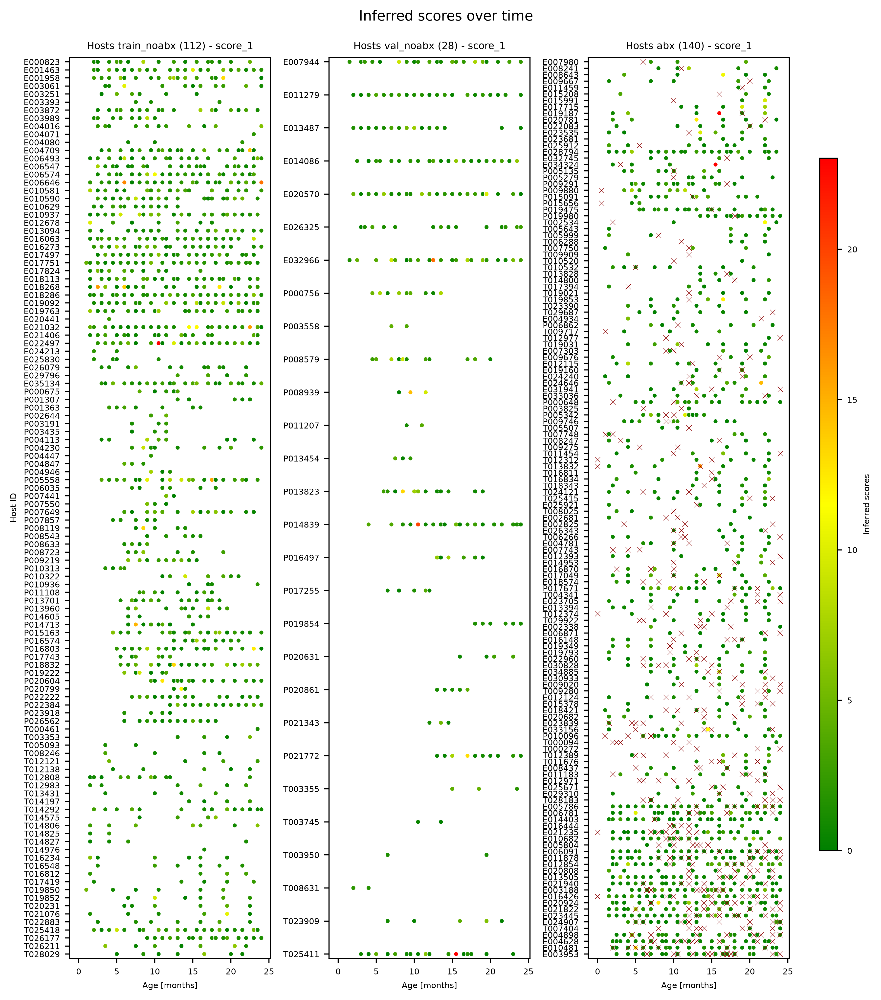

In [25]:
dic_splits = {
    "train_noabx": ["score_1", noabx_train, None],
    "val_noabx": ["score_1", noabx_val, None],
    "abx": ["score_1", abx_scores_flat, abx_events],
}

display_scatterplot_w_scores(
    dic_splits, False, path_to_output=evaluation_path, flag="noabx_vs_abx"
)

/cluster/project/bokulich/adamova/Probabilistic_forecasting_for_Anomaly_Detection/src/utils_eval_score.py:835: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


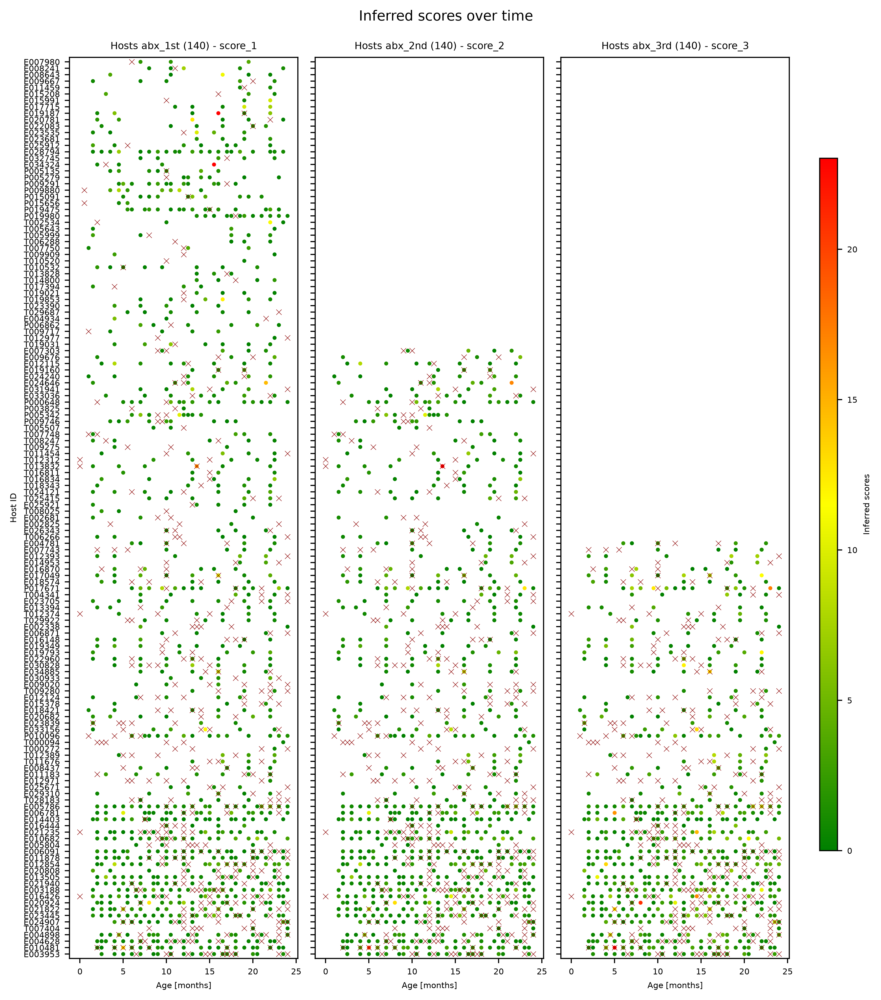

In [26]:
dic_splits = {
    "abx_1st": ["score_1", abx_scores_flat, abx_events],
    "abx_2nd": ["score_2", abx_scores_flat, abx_events],
    "abx_3rd": ["score_3", abx_scores_flat, abx_events],
}

display_scatterplot_w_scores(
    dic_splits, False, True, path_to_output=evaluation_path, flag="all_abx"
)

## Individual score trajectories

### abx

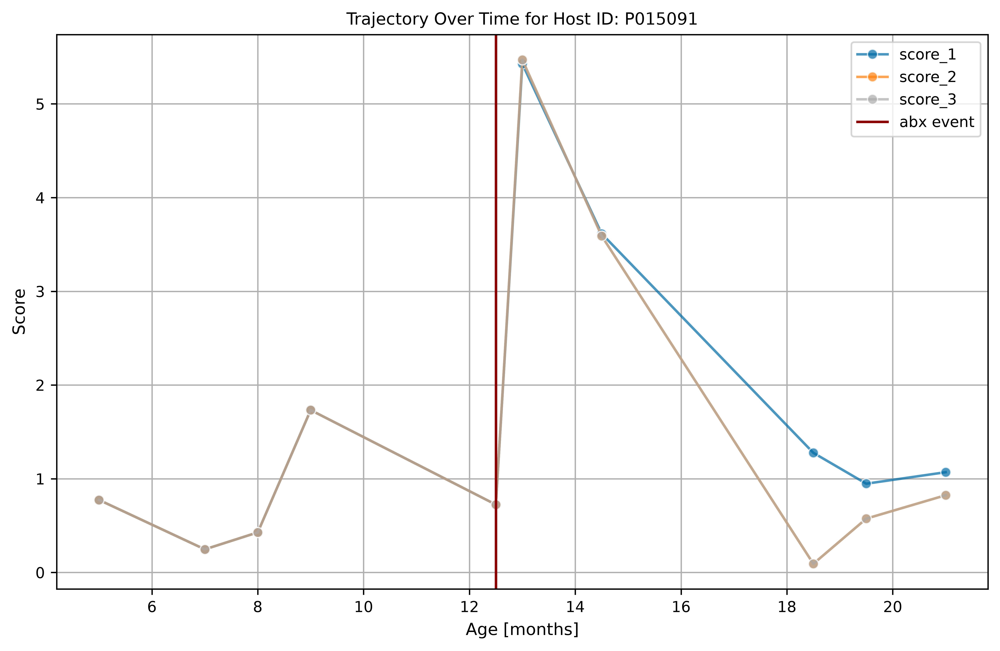

In [27]:
plot_trajectory(
    abx_scores_flat,
    abx_events,
    "P015091",
    ["score_1", "score_2", "score_3"],
    path_to_output=evaluation_path,
    flag="all_scores",
)

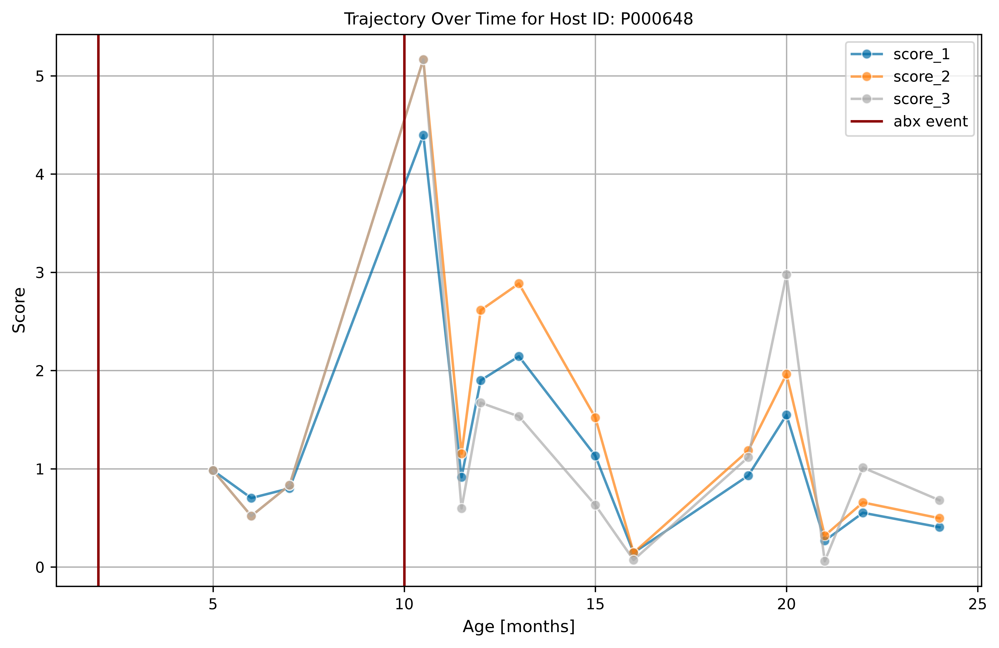

In [28]:
plot_trajectory(
    abx_scores_flat,
    abx_events,
    "P000648",
    ["score_1", "score_2", "score_3"],
    path_to_output=evaluation_path,
    flag="all_scores",
)

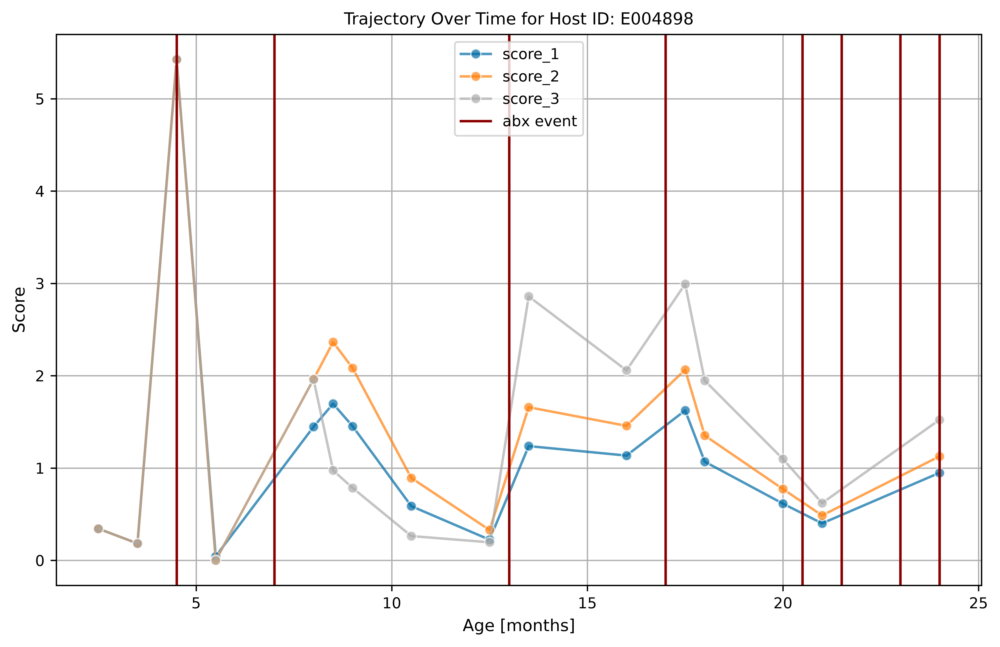

In [29]:
plot_trajectory(
    abx_scores_flat,
    abx_events,
    "E004898",
    ["score_1", "score_2", "score_3"],
    path_to_output=evaluation_path,
    flag="all_scores",
)

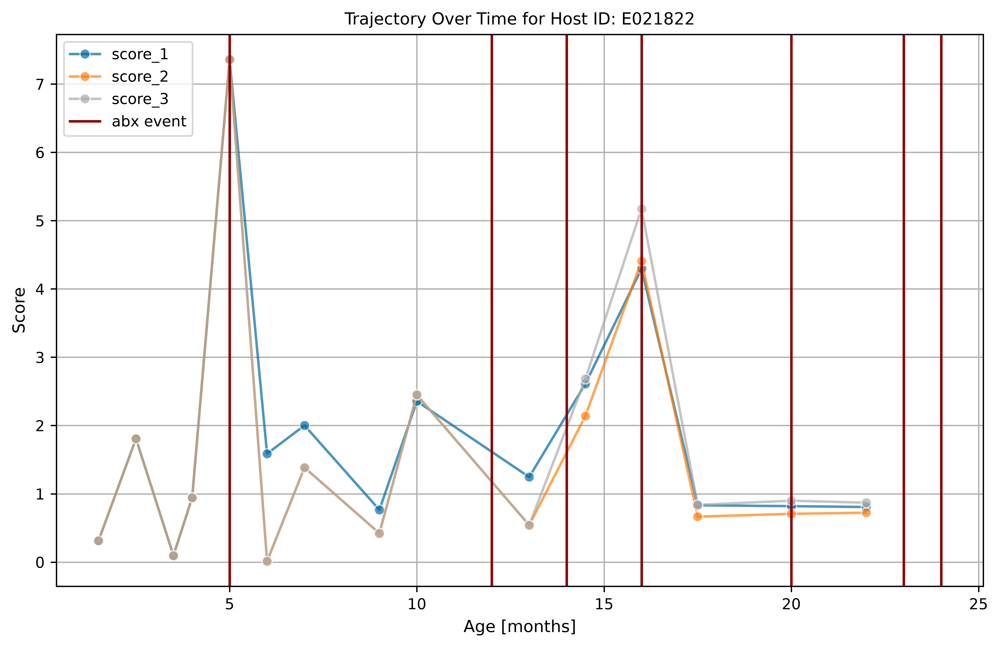

In [30]:
plot_trajectory(
    abx_scores_flat,
    abx_events,
    "E021822",
    ["score_1", "score_2", "score_3"],
    path_to_output=evaluation_path,
    flag="all_scores",
)

### noabx

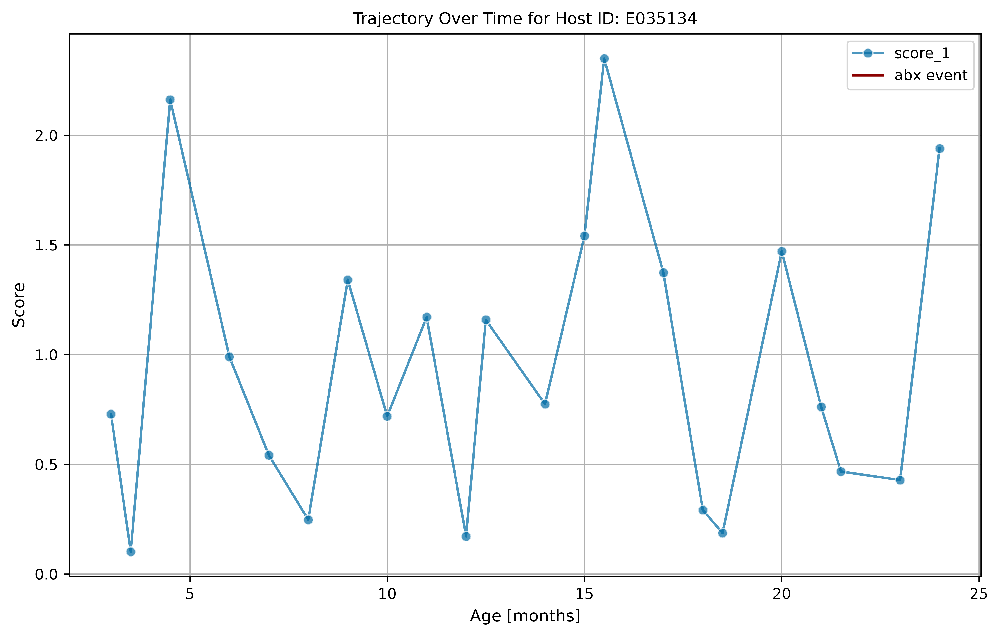

In [31]:
plot_trajectory(
    noabx_train,
    None,
    "E035134",
    ["score_1"],
    path_to_output=evaluation_path,
    flag="noabx_score1",
)

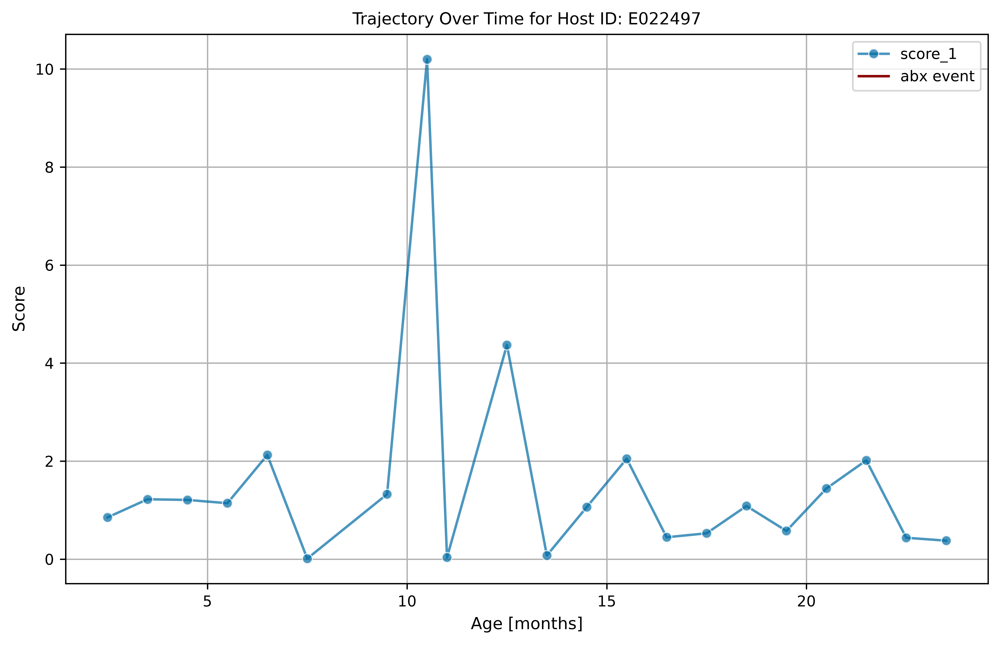

In [32]:
plot_trajectory(
    noabx_train,
    None,
    "E022497",
    ["score_1"],
    path_to_output=evaluation_path,
    flag="noabx_score1",
)